[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/MFM/blob/main/notebooks/RO/capitol10_notebook_seminar.ipynb)

# Modelarea piețelor financiare — Seminarul 10: Microstructura pieței

*Notebook de seminar. Daniel Traian Pele, Antoaneta Amza, Academia de Studii Economice din București.*

- Problemele **[Rezolvat]** conțin rezolvarea completă; problemele **[Propus]** le rezolvați dumneavoastră.
- Exerciții de bază: A1–A2, B1–B4, C1; pachete de extindere: A3–A10, B5–B8, C2, C3.

> Rezolvările se discută la seminar.

> **Working in Google Colab? Save your own copy first.**
> The Colab link opens a temporary copy: when you close the tab or the session times out, your changes are lost.
> Use **File → Save a copy in Drive** (it goes to the *Colab Notebooks* folder of your ASE Google Drive) and work in that copy.
> For the team project, **File → Save a copy in GitHub** puts the notebook directly in your team's repository.
> Files you create while the notebook runs (CSV, charts) are also temporary: set `SAVE_TO_DRIVE = True` in the next cell to keep them.

In [1]:
# Optional (Colab only): keep the files you create in Google Drive
SAVE_TO_DRIVE = False   # set to True, run this cell and allow access to your Drive

import os
OUT_DIR = '.'
if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    OUT_DIR = '/content/drive/MyDrive/MFM/Chapter_10'
    os.makedirs(OUT_DIR, exist_ok=True)
    os.chdir(OUT_DIR)  # relative chart and CSV outputs persist in Drive
print('Save your outputs to:', os.path.abspath(OUT_DIR))


## Exerciții

[A1](#exercise-a1) · [A2](#exercise-a2) · [A3](#exercise-a3) · [A4](#exercise-a4) · [A5](#exercise-a5) · [A6](#exercise-a6) · [A7](#exercise-a7) · [A8](#exercise-a8) · [A9](#exercise-a9) · [A10](#exercise-a10) · [B1](#exercise-b1) · [B2](#exercise-b2) · [B3](#exercise-b3) · [B4](#exercise-b4) · [B5](#exercise-b5) · [B6](#exercise-b6) · [B7](#exercise-b7) · [B8](#exercise-b8) · [C2](#exercise-c2) · [C1](#exercise-c1) · [C3](#exercise-c3)

In [2]:
import os
import re
import json
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

Matplotlib is building the font cache; this may take a moment.


## Stil și funcții ajutătoare

In [3]:
# Chart style: transparent background, legend below the plot
plt.rcParams['figure.facecolor'] = 'none'
plt.rcParams['axes.facecolor'] = 'none'
plt.rcParams['savefig.facecolor'] = 'none'
plt.rcParams['savefig.transparent'] = True
plt.rcParams['axes.grid'] = False
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Helvetica', 'Arial', 'DejaVu Sans']
plt.rcParams['font.size'] = 9
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['axes.titlesize'] = 11
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.linewidth'] = 0.6
plt.rcParams['lines.linewidth'] = 1.1
plt.rcParams['legend.facecolor'] = 'none'
plt.rcParams['legend.framealpha'] = 0
plt.rcParams['legend.fontsize'] = 8

# Colours
MainBlue = '#1A3A6E'
IDAred   = '#CD0000'
Forest   = '#2E7D32'
Amber    = '#B5853F'
Orange   = '#E67E22'
Purple   = '#8E44AD'
Crimson  = '#DC3545'
Teal     = '#17A2B8'
Navy     = '#1F2A44'   # reference lines (no grey in charts)
BandBlue = '#C5D2E8'   # light MainBlue tint for confidence / reference bands
Gray, LightGray = Navy, BandBlue   # legacy names kept for importing scripts
GROUP_COL = {'US': MainBlue, 'BVB': IDAred, 'Crypto': Amber}

HERE = '.'
SEED = 42
START2 = '2024-09-19'
START10 = '2016-09-19'
B_BOOT = 1000



def save_fig(name):
    """Afiseaza figura."""
    if globals().get("SAVE_TO_DRIVE", False):
        plt.savefig(os.path.join(globals().get("OUT_DIR", "."), name + ".png"), dpi=180, bbox_inches="tight", transparent=True)
    plt.show()
    plt.close()


def legend_outside_bottom(ax, ncol=2, y=-0.22):
    """Place the legend outside the plot, bottom centre."""
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, y), ncol=ncol, frameon=False)


def fig_legend_bottom(fig, handles, labels, ncol=3, y=0.0):
    """A single legend for a multi-panel figure, below the figure."""
    fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, y), ncol=ncol, frameon=False)


def jsonable(o):
    if isinstance(o, dict):
        return {str(k): jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple, np.ndarray)):
        return [jsonable(v) for v in o]
    if isinstance(o, (np.floating, np.integer)):
        return o.item()
    if isinstance(o, (np.bool_,)):
        return bool(o)
    return o

## Date

- Bare SPY de 5 minute, sesiunea regulată (09:30–16:00, ora New York), octombrie 2020 – septembrie 2026; bare Bitcoin de 5 minute (Coordinated Universal Time (UTC)), 31 august 2024 – 18 septembrie 2026.
- Deschidere, maxim, minim, închidere și volum zilnic pentru acțiuni americane, acțiuni de la Bursa de Valori București (BVB) și cripto-active; prețuri ajustate pentru dividende și divizări.
- Valorile tranzacționate la BVB convertite din lei în USD la cursul de referință al Băncii Naționale a României (BNR); valorile cripto sînt în USD.

In [4]:
REPO_RAW = 'https://raw.githubusercontent.com/danpele/MFM/main/data/market/'
# use the local copy of the course data when the notebook runs inside the repository
MARKET_DIR = next((os.path.join(d, 'data', 'market') for d in ('.', '..', '../..', '../../..')
                   if os.path.isdir(os.path.join(d, 'data', 'market'))), '')
END = '2026-09-18'

# key -> (symbol, label, group)
ASSETS = {
    'SPY': ('SPY.US', 'SPY', 'US'), 'AAPL': ('AAPL.US', 'Apple', 'US'), 'MSFT': ('MSFT.US', 'Microsoft', 'US'),
    'NVDA': ('NVDA.US', 'NVIDIA', 'US'), 'JPM': ('JPM.US', 'JPMorgan', 'US'), 'GME': ('GME.US', 'GameStop', 'US'),
    'MSTR': ('MSTR.US', 'Strategy', 'US'),
    'TLV': ('TLV.RO', 'Banca Transilvania', 'BVB'), 'SNP': ('SNP.RO', 'OMV Petrom', 'BVB'),
    'H2O': ('H2O.RO', 'Hidroelectrica', 'BVB'), 'BRD': ('BRD.RO', 'BRD', 'BVB'), 'SNG': ('SNG.RO', 'Romgaz', 'BVB'),
    'SNN': ('SNN.RO', 'Nuclearelectrica', 'BVB'), 'TGN': ('TGN.RO', 'Transgaz', 'BVB'),
    'EL': ('EL.RO', 'Electrica', 'BVB'), 'DIGI': ('DIGI.RO', 'Digi', 'BVB'), 'TEL': ('TEL.RO', 'Transelectrica', 'BVB'),
    'TVBETETF': ('TVBETETF.RO', 'BET ETF', 'BVB'),
    'BTC': ('BTC-USD.CC', 'Bitcoin', 'Crypto'), 'ETH': ('ETH-USD.CC', 'Ethereum', 'Crypto'),
    'SOL': ('SOL-USD.CC', 'Solana', 'Crypto'), 'XRP': ('XRP-USD.CC', 'XRP', 'Crypto'),
    'DOGE': ('DOGE-USD.CC', 'Dogecoin', 'Crypto'), 'ADA': ('ADA-USD.CC', 'Cardano', 'Crypto'),
    'LTC': ('LTC-USD.CC', 'Litecoin', 'Crypto'),
}
GROUPS = {g: [k for k, v in ASSETS.items() if v[2] == g] for g in ('US', 'BVB', 'Crypto')}
LABELS = {k: v[1] for k, v in ASSETS.items()}
# large adjustment events that are cash dividends, not splits (issuer announcement):
#   SNN.RO 2018-12-21: gross dividend of 1.61 lei per share, ex-date 21 December 2018
#   (https://www.nuclearelectrica.ro/wp-content/uploads/2018/12/SNN_Comunicat-plata-dividende-suplimentare_EN.pdf)
CASH_DIVIDENDS = {'SNN.RO': ['2018-12-21']}

_CACHE = {}


def read_market(symbol):
    """Read the daily price file of one symbol, from a local copy or from the GitHub repository."""
    if symbol in _CACHE:
        return _CACHE[symbol]
    fname = f'{symbol}.csv'
    path = os.path.join(MARKET_DIR, fname)
    src = path if os.path.exists(path) else REPO_RAW + fname
    _CACHE[symbol] = pd.read_csv(src, index_col='date', parse_dates=True).sort_index()
    return _CACHE[symbol]


def read_reference_rate(currency='USD', start='2014-01-01', end=END):
    """Official RON reference rate (BNR yearly XML archives)."""
    key = ('REF', currency, start, end)
    if key in _CACHE:
        return _CACHE[key]
    rows = []
    for y in range(int(start[:4]), int(end[:4]) + 1):
        url = f'https://curs.bnr.ro/files/xml/years/nbrfxrates{y}.xml'
        xml = urllib.request.urlopen(urllib.request.Request(url, headers={'User-Agent': 'Mozilla'}),
                                     timeout=60).read().decode()
        for d, body in re.findall(r'<Cube date="([\d-]+)">(.*?)</Cube>', xml, re.S):
            m = re.search(rf'<Rate currency="{currency}">([\d.]+)</Rate>', body)
            if m:
                rows.append((d, float(m.group(1))))
    s = pd.DataFrame(rows, columns=['date', 'rate']).drop_duplicates('date').set_index('date')['rate']
    s.index = pd.to_datetime(s.index)
    _CACHE[key] = s.sort_index().loc[start:end]
    return _CACHE[key]


def _clean(key, d):
    d = d[(d['high'] > d['low']) & (d['volume'].fillna(0) > 0)]
    if ASSETS[key][2] != 'Crypto':
        d = d[d.index.dayofweek < 5]
        # isolated bad ticks: adjusted price more than twice / less than half the local median (21 days)
        med = d['adjusted_close'].rolling(21, center=True, min_periods=5).median()
        d = d[np.abs(np.log(d['adjusted_close'] / med)) < np.log(2)]
    return d


def ohlc(key, start='2016-09-19', end=END):
    """Open, high, low, close scaled by the adjustment factor of the adjusted price (dividends and splits)."""
    d = read_market(ASSETS[key][0]).loc[start:end].copy()
    f = d['adjusted_close'] / d['close']
    for c in ['open', 'high', 'low', 'close']:
        d[c] = d[c] * f
    return _clean(key, d)[['open', 'high', 'low', 'close', 'volume']]


def split_adjusted_close(d, symbol=None):
    """Close price adjusted ONLY for splits and bonus shares (same basis as the volume in number of shares);
    the large cash dividends in CASH_DIVIDENDS are not treated as splits."""
    k = (d['close'].shift(1) / d['close']) / (d['adjusted_close'].shift(1) / d['adjusted_close'])
    k = k.where(np.abs(np.log(k)) > 0.15, 1.0).fillna(1.0)      # split days: the split ratio
    for day in CASH_DIVIDENDS.get(symbol, []):
        k.loc[k.index == pd.Timestamp(day)] = 1.0
    back = k[::-1].cumprod()[::-1].shift(-1).fillna(1.0)          # product of the splits after each day
    return d['close'] / back


def returns(key, start='2016-09-19', end=END):
    """Daily log returns from the adjusted price (days without trading dropped)."""
    d = read_market(ASSETS[key][0]).loc[start:end]
    d = _clean(key, d)
    return np.log(d['adjusted_close']).diff().dropna().rename(key)


def dollar_volume(key, start='2016-09-19', end=END):
    """Daily traded value, in USD."""
    d = read_market(ASSETS[key][0]).loc[:end]
    grp = ASSETS[key][2]
    if grp == 'Crypto':
        dv = d['volume']                                          # already in USD
    else:
        dv = split_adjusted_close(d, ASSETS[key][0]) * d['volume']
        if grp == 'BVB':                                          # RON -> USD at the BNR reference rate
            fx = read_reference_rate('USD', start='2014-01-01', end=end)
            dv = dv / fx.reindex(dv.index).ffill()
    d = _clean(key, d.assign(dv=dv))
    return d['dv'].loc[start:end].dropna().rename(key)


def intraday_spy():
    """SPY 5-minute bars, regular session (09:30-15:55 = bar start), complete days only (78 bars)."""
    fname = 'intraday/SPY.US_5m.csv'
    path = os.path.join(MARKET_DIR, fname)
    d = pd.read_csv(path if os.path.exists(path) else REPO_RAW + fname, parse_dates=['datetime_utc'])
    t = d['datetime_utc'].dt.tz_localize('UTC').dt.tz_convert('America/New_York').dt.tz_localize(None)
    d = d.assign(t=t, date=t.dt.normalize(), tod=t.dt.strftime('%H:%M')).drop(columns='datetime_utc')
    d = d[(d['tod'] >= '09:30') & (d['tod'] <= '15:55')]
    n = d.groupby('date').size()
    d = d[d['date'].isin(n[n == 78].index)].set_index('t').sort_index()
    d['r'] = np.log(d['close']).groupby(d['date']).diff()
    first = d['tod'] == '09:30'
    d.loc[first, 'r'] = np.log(d.loc[first, 'close'] / d.loc[first, 'open'])   # first bar: from the open
    d['dv'] = d['close'] * d['volume']
    return d


def intraday_btc():
    """Bitcoin 5-minute bars (UTC), 24 hours a day; volume is not used (missing on many bars)."""
    fname = 'intraday/BTC-USD.CC_5m.csv'
    path = os.path.join(MARKET_DIR, fname)
    d = pd.read_csv(path if os.path.exists(path) else REPO_RAW + fname, parse_dates=['datetime_utc'])
    d = d.set_index('datetime_utc').sort_index()
    d = d[~d.index.duplicated()]
    d['date'] = d.index.normalize()
    d['r'] = np.log(d['close']).diff()
    gap = d.index.to_series().diff() != pd.Timedelta('5min')
    d.loc[gap, 'r'] = np.nan                                       # no returns across missing bars
    return d

## Estimatori și modele

- `roll_spread`, `cs_spread`, `ar_terms`, `edge_spread`, `amihud`: măsuri ale spread-ului și ale ilichidității; `roll_mc`: Monte Carlo pentru modelul Roll.
- `price_discovery`: ponderile informaționale dintr-un model vectorial cu corecția erorilor (VECM); `pin_loglik`: verosimilitatea probabilității de tranzacționare informată (Probability of Informed Trading (PIN)) în formă stabilă.
- `walk_book`, `zi_simulate`: execuția pe registrul de ordine și un registru simulat.
- `gm_quotes`, `gm_simulate`, `kyle`, `ac_trajectory`, `ac_frontier`: Glosten–Milgrom, Kyle și Almgren–Chriss.

In [5]:
def roll_spread(close):
    """Roll relative spread from the first-order autocovariance of log returns; NaN if the covariance is positive."""
    r = np.log(np.asarray(close, float))
    dp = np.diff(r)
    c = np.mean((dp[1:] - dp.mean()) * (dp[:-1] - dp.mean()))
    return (2 * np.sqrt(-c) if c < 0 else np.nan), c


def cs_spread(high, low, close=None):
    """Corwin-Schultz estimator for each pair of consecutive periods (negative values set to 0).
    With close (daily data): the overnight adjustment of Corwin and Schultz (2012): if the low of day t+1 is above
    the close of day t, the high and low of t+1 are lowered by the difference; if the high of t+1 is below the close
    of t, both are raised by the difference. Intraday bars of the same session are not adjusted."""
    H, L = np.asarray(high, float), np.asarray(low, float)
    h0, l0, h1, l1 = H[:-1], L[:-1], H[1:].copy(), L[1:].copy()
    if close is not None:
        c0 = np.asarray(close, float)[:-1]
        up = l1 > c0
        d = np.where(up, l1 - c0, 0.0)
        h1, l1 = h1 - d, l1 - d
        dn = h1 < c0
        d = np.where(dn, c0 - h1, 0.0)
        h1, l1 = h1 + d, l1 + d
    beta = np.log(h0 / l0) ** 2 + np.log(h1 / l1) ** 2
    gamma = np.log(np.maximum(h0, h1) / np.minimum(l0, l1)) ** 2
    k = 3 - 2 * np.sqrt(2)
    alpha = (np.sqrt(2 * beta) - np.sqrt(beta)) / k - np.sqrt(gamma / k)
    return np.clip(2 * (np.exp(alpha) - 1) / (1 + np.exp(alpha)), 0, None)


def ar_terms(close, high, low):
    """Abdi-Ranaldo terms: 4 (c_t - eta_t)(c_t - eta_{t+1}); their mean estimates s^2."""
    c = np.log(np.asarray(close, float))
    eta = (np.log(np.asarray(high, float)) + np.log(np.asarray(low, float))) / 2
    return 4 * (c[:-1] - eta[:-1]) * (c[:-1] - eta[1:])


def ar_spread(close, high, low):
    """Abdi-Ranaldo relative spread: sqrt(max(mean of the terms, 0))."""
    m = np.mean(ar_terms(close, high, low))
    return np.sqrt(max(m, 0.0)), m


def edge_spread(open_, high, low, close, sign=True):
    """EDGE (Ardia, Guidotti and Kroencke, 2024, JFE 161, 103916): relative spread from OHLC prices.
    Follows the authors' reference implementation (bidask package, MIT licence). sign=True returns the signed
    estimate; for averages over several windows, each negative window estimate is set to zero before averaging."""
    o, h, l, c = (np.log(np.asarray(x, float)) for x in (open_, high, low, close))
    if len(o) < 3:
        return np.nan
    m = (h + l) / 2.
    h1, l1, c1, m1 = h[:-1], l[:-1], c[:-1], m[:-1]
    o, h, l, c, m = o[1:], h[1:], l[1:], c[1:], m[1:]
    r1, r2, r3, r4, r5 = m - o, o - m1, m - c1, c1 - m1, o - c1
    tau = np.where(np.isnan(h) | np.isnan(l) | np.isnan(c1), np.nan, (h != l) | (l != c1))
    po1 = tau * np.where(np.isnan(o) | np.isnan(h), np.nan, o != h)
    po2 = tau * np.where(np.isnan(o) | np.isnan(l), np.nan, o != l)
    pc1 = tau * np.where(np.isnan(c1) | np.isnan(h1), np.nan, c1 != h1)
    pc2 = tau * np.where(np.isnan(c1) | np.isnan(l1), np.nan, c1 != l1)
    pt = np.nanmean(tau)
    po = np.nanmean(po1) + np.nanmean(po2)
    pc = np.nanmean(pc1) + np.nanmean(pc2)
    if np.nansum(tau) < 2 or po == 0 or pc == 0:
        return np.nan
    d1 = r1 - np.nanmean(r1) / pt * tau
    d3 = r3 - np.nanmean(r3) / pt * tau
    d5 = r5 - np.nanmean(r5) / pt * tau
    x1 = -4. / po * d1 * r2 - 4. / pc * d3 * r4
    x2 = -4. / po * d1 * r5 - 4. / pc * d5 * r4
    e1, e2 = np.nanmean(x1), np.nanmean(x2)
    v1, v2 = np.nanmean(x1 ** 2) - e1 ** 2, np.nanmean(x2 ** 2) - e2 ** 2
    vt = v1 + v2
    s2 = (v2 * e1 + v1 * e2) / vt if vt > 0 else (e1 + e2) / 2.
    s = np.sqrt(np.abs(s2))
    return float(s * np.sign(s2)) if sign else float(s)


def amihud(r, dv, scale=1e6):
    """Amihud illiquidity: mean |r| (basis points) per USD 1 million traded."""
    x = pd.concat([r.rename('r'), dv.rename('dv')], axis=1, join='inner').dropna()
    x = x[x['dv'] > 0]
    return float((1e4 * x['r'].abs() / (x['dv'] / scale)).mean())


def daily_estimates(d, overnight=True):
    """Spread estimators over a window of bars: overnight=True for daily data (Corwin-Schultz overnight
    adjustment), overnight=False for the intraday bars of one session."""
    rs, cov = roll_spread(d['close'])
    cs = cs_spread(d['high'], d['low'], d['close'] if overnight else None)
    ar2 = ar_terms(d['close'], d['high'], d['low'])
    return pd.Series(dict(cov=cov, roll=rs, cs=cs.mean(), ar2=ar2.mean()))


def roll_mc(c, sigma, T=78, R=20000, seed=42):
    """Harris (1990): simulate the Roll model (m_t a random walk with N(0, sigma^2) steps, q_t = +-1 with prob. 1/2)
    over T prices and compute the first-order autocovariance of the (demeaned) changes, as on real data."""
    rng = np.random.default_rng(seed)
    p = np.cumsum(rng.normal(0, sigma, (R, T)), axis=1) + c * np.where(rng.random((R, T)) < 0.5, 1, -1)
    dp = np.diff(p, axis=1)
    dm = dp - dp.mean(axis=1, keepdims=True)
    return (dm[:, 1:] * dm[:, :-1]).mean(axis=1)


def price_discovery(y, p=1):
    """Bivariate VECM with the cointegrating vector (1, -1) imposed: dy_t = a0 + alpha (y1 - y2)_{t-1} + sum Gamma_i dy_{t-i} + e_t.
    Returns alpha, the t statistics, the Gonzalo-Granger component share (normalised alpha_perp) and the bounds
    of the Hasbrouck information share (the two Cholesky orderings)."""
    y = np.asarray(y, float)
    dy = np.diff(y, axis=0)
    z = (y[:, 0] - y[:, 1])[:-1]
    X = np.array([[1.0, z[t]] + [v for i in range(1, p + 1) for v in dy[t - i]] for t in range(p, len(dy))])
    Y = dy[p:]
    B = np.linalg.lstsq(X, Y, rcond=None)[0]
    U = Y - X @ B
    Om = U.T @ U / (len(U) - X.shape[1])
    alpha = B[1]
    se = np.sqrt(np.linalg.inv(X.T @ X)[1, 1] * np.diag(Om))
    ap = np.array([-alpha[1], alpha[0]])                       # alpha_perp: alpha' alpha_perp = 0
    cs = ap / ap.sum()
    psi = ap                                                    # common row of the long-run impact matrix (up to scale)
    IS = []
    for order in ([0, 1], [1, 0]):
        F = np.linalg.cholesky(Om[np.ix_(order, order)])
        v = (psi[order] @ F) ** 2 / (psi @ Om @ psi)
        IS.append(v[np.argsort(order)])
    IS = np.array(IS)
    return dict(alpha=alpha, t=alpha / se, cs=cs, is_lo=IS.min(axis=0), is_hi=IS.max(axis=0),
                corr=float(Om[0, 1] / np.sqrt(Om[0, 0] * Om[1, 1])), resid=U, n=len(U))


def pin_loglik(B, S, alpha, delta, mu, eb, es):
    """EKOP log-likelihood of a day with B buys and S sells, in the factorised form that avoids
    numerical overflow (Lin and Ke, 2011): ln L = -eb - es + B ln(mu + eb) + S ln(mu + es) - ln B! - ln S!
    + ln[(1 - alpha) xb^B xs^S + alpha delta e^-mu xb^B + alpha (1 - delta) e^-mu xs^S], xb = eb / (mu + eb)."""
    from scipy.special import gammaln, logsumexp
    lxb, lxs = np.log(eb / (mu + eb)), np.log(es / (mu + es))
    terms = [np.log(1 - alpha) + B * lxb + S * lxs, np.log(alpha * delta) - mu + B * lxb,
             np.log(alpha * (1 - delta)) - mu + S * lxs]
    base = -eb - es + B * np.log(mu + eb) + S * np.log(mu + es) - gammaln(B + 1) - gammaln(S + 1)
    return float(base + logsumexp(terms)), terms


def walk_book(asks, qty):
    """Market buy order of size qty against the sell offers asks = [(price, quantity), ...] in ascending order.
    Returns the fills, the volume-weighted average price and the remaining offers."""
    fills, left, rest = [], qty, []
    for p, q in asks:
        if left <= 0:
            rest.append((p, q))
            continue
        take = min(q, left)
        fills.append((p, take))
        left -= take
        if q > take:
            rest.append((p, q - take))
    vwap = sum(p * q for p, q in fills) / sum(q for _, q in fills)
    return fills, vwap, rest, left


def gm_quotes(theta, mu, vl, vh):
    """Ask and bid quotes: expected value conditional on a buy and on a sell, respectively.
    theta = P(V = vh), mu = share of informed traders; uninformed traders buy or sell with prob. 1/2."""
    pb_h, pb_l = mu + (1 - mu) / 2, (1 - mu) / 2               # P(buy | V = vh), P(buy | V = vl)
    th_b = pb_h * theta / (pb_h * theta + pb_l * (1 - theta))   # P(V = vh | buy)
    th_s = pb_l * theta / (pb_l * theta + pb_h * (1 - theta))   # P(V = vh | sell)
    return vl + th_b * (vh - vl), vl + th_s * (vh - vl), th_b, th_s


def gm_simulate(mu, vl=90.0, vh=110.0, v=110.0, n=60, seed=1):
    """A sequence of trades when the true value is v; the market maker learns from the order flow."""
    rng = np.random.default_rng(seed)
    theta, rows = 0.5, []
    for t in range(n):
        ask, bid, th_b, th_s = gm_quotes(theta, mu, vl, vh)
        informed = rng.random() < mu
        buy = (v == vh) if informed else (rng.random() < 0.5)
        rows.append(dict(t=t, ask=ask, bid=bid, theta=theta, buy=buy))
        theta = th_b if buy else th_s
    return pd.DataFrame(rows)


def kyle(sigma_v, sigma_u):
    """Kyle equilibrium: v ~ N(p0, sigma_v^2), noise-trader demand u ~ N(0, sigma_u^2).
    Informed strategy x = beta (v - p0), price p = p0 + lambda (x + u)."""
    beta = sigma_u / sigma_v
    lam = sigma_v / (2 * sigma_u)
    profit = sigma_v * sigma_u / 2
    return dict(beta=beta, lam=lam, profit=profit, post_var=sigma_v ** 2 / 2)


def ac_trajectory(X, T, N, sigma, eta, gamma, lam, eps=0.0):
    """Optimal liquidation trajectory (exact discrete-time formulas).
    X shares to sell in T days, N intervals; sigma = price volatility (USD / day^0.5);
    temporary impact h(v) = eps sgn + eta v; permanent impact g(v) = gamma v; lam = risk aversion."""
    tau = T / N
    eta_t = eta - gamma * tau / 2
    t = np.arange(N + 1) * tau
    if lam == 0:
        x = X * (1 - t / T)
    else:
        kt2 = lam * sigma ** 2 / eta_t                       # kappa_tilde^2
        kappa = np.arccosh(kt2 * tau ** 2 / 2 + 1) / tau
        x = X * np.sinh(kappa * (T - t)) / np.sinh(kappa * T)
    n = -np.diff(x)
    E = 0.5 * gamma * X ** 2 + eps * X + eta_t / tau * np.sum(n ** 2)
    V = sigma ** 2 * tau * np.sum(x[1:] ** 2)
    return t, x, E, V


def ac_frontier(X, T, N, sigma, eta, gamma, lams):
    """Efficient frontier (standard deviation, expected cost) for several risk aversions."""
    out = []
    for lam in lams:
        _, _, E, V = ac_trajectory(X, T, N, sigma, eta, gamma, lam)
        out.append((lam, E, np.sqrt(V)))
    return pd.DataFrame(out, columns=['lam', 'E', 'sd'])


def zi_simulate(n_events=300_000, L=40, rate_limit=1.0, rate_market=0.25, rate_cancel=0.025, n_ticks=4000, seed=7):
    """Limit orders (uniform over L ticks from the opposite quote), market orders and cancellations, all of one unit.
    Returns the (mid, spread) series and snapshots of the book."""
    rng = np.random.default_rng(seed)
    bid_q = np.zeros(n_ticks, int)
    ask_q = np.zeros(n_ticks, int)
    mid0 = n_ticks // 2
    bid_q[mid0 - 20:mid0] = 3
    ask_q[mid0 + 1:mid0 + 21] = 3
    rows, snaps, offset = [], [], 0
    for e in range(n_events):
        bb = np.flatnonzero(bid_q)[-1]
        ba = np.flatnonzero(ask_q)[0]
        n_orders = bid_q.sum() + ask_q.sum()
        w = np.array([2 * L * rate_limit, 2 * rate_market, rate_cancel * n_orders])
        u = rng.random() * w.sum()
        side = rng.random() < 0.5
        if u < w[0]:                                   # limit order
            k = rng.integers(1, L + 1)
            if side:
                p = ba - k
                bid_q[p] += 1
            else:
                p = bb + k
                ask_q[p] += 1
        elif u < w[0] + w[1]:                          # market order
            if side:
                ask_q[ba] -= 1 if ask_q[ba] > 0 else 0
            else:
                bid_q[bb] -= 1 if bid_q[bb] > 0 else 0
        else:                                          # cancel an existing order, chosen uniformly among all orders
            side = rng.random() < bid_q.sum() / n_orders   # side chosen in proportion to the number of resting orders
            if side and bid_q.sum() > 1:
                idx = rng.choice(np.flatnonzero(bid_q), p=bid_q[bid_q > 0] / bid_q.sum())
                bid_q[idx] -= 1
            elif (not side) and ask_q.sum() > 1:
                idx = rng.choice(np.flatnonzero(ask_q), p=ask_q[ask_q > 0] / ask_q.sum())
                ask_q[idx] -= 1
        if not bid_q.any():
            bid_q[bb] = 1
        if not ask_q.any():
            ask_q[ba] = 1
        bb = np.flatnonzero(bid_q)[-1]
        ba = np.flatnonzero(ask_q)[0]
        if bb < 5 * L or ba > n_ticks - 5 * L:         # recentre: the book stays in the middle of the grid
            sh = int((bb + ba) / 2 - n_ticks // 2)
            bid_q, ask_q = np.roll(bid_q, -sh), np.roll(ask_q, -sh)
            if sh > 0:
                bid_q[-sh:] = 0
                ask_q[-sh:] = 0
            else:
                bid_q[:-sh] = 0
                ask_q[:-sh] = 0
            offset += sh
        if e % 50 == 0:
            bb = np.flatnonzero(bid_q)[-1]
            ba = np.flatnonzero(ask_q)[0]
            rows.append((e, (bb + ba) / 2 - mid0 + offset, ba - bb))
        if e > n_events // 3 and e % 1000 == 0:
            bb = np.flatnonzero(bid_q)[-1]
            ba = np.flatnonzero(ask_q)[0]
            m = (bb + ba) / 2
            rel = np.arange(n_ticks) - m
            sel = np.abs(rel) <= 30
            snaps.append(pd.DataFrame({'rel': rel[sel], 'bid': bid_q[sel], 'ask': ask_q[sel]}))
    path = pd.DataFrame(rows, columns=['event', 'mid', 'spread'])
    return path, snaps, (bid_q, ask_q)

## Funcțiile seminarului

- Parametrii din Partea A, bootstrap-ul pe zile și tabelele folosite în Partea B.

In [6]:
B = 1000
AC = {'X': 1000000.0, 'T': 5, 'N': 5, 'sigma': 0.95, 'eta': 2.5e-06, 'gamma': 2.5e-07}
C_MARKETS = {'BVB': {'ret': ('BETTR.INDX', 'close'), 'keys': ['TLV', 'SNP', 'H2O', 'BRD', 'SNG', 'SNN', 'TGN', 'EL', 'DIGI', 'TEL']}, 'US': {'ret': ('SPY.US', 'adjusted_close'), 'keys': ['AAPL', 'MSFT', 'NVDA', 'JPM', 'GME', 'MSTR']}, 'Crypto': {'ret': ('BTC-USD.CC', 'close'), 'keys': ['ETH', 'SOL', 'XRP', 'DOGE', 'ADA', 'LTC']}}
PIN_PAR = {'alpha': 0.3, 'delta': 0.5, 'mu': 400.0, 'eb': 1000.0, 'es': 1000.0}
PD_START = '2024-09-19'
END_PD = '2026-09-18'
PIN_DAYS = [('A9: B = 1450, S = 1000', 1450, 1000), ('A10(a): B = 1000, S = 1420', 1000, 1420), ('A10(b): B = S = 1000', 1000, 1000), ('A10(c): B = 1195, S = 1000', 1195, 1000)]
ABO = {'col2': 0.4213, 'col6_v': 0.3354, 'col6_s': 0.0066, 'lo': 0.2, 'hi': 0.74, 'tax_lse': 0.419}
YEARS = (2021, 2025)


def boot_days(values_by_day, stat, B=B, seed=SEED, draws=False):
    """Day bootstrap (blocks = whole days): 95% percentile interval for stat(sample of days).
    draws=True also returns the values of the B resamples."""
    rng = np.random.default_rng(seed)
    days = np.array(list(values_by_day.keys()))
    out = []
    for _ in range(B):
        pick = rng.choice(days, len(days), replace=True)
        out.append(stat([values_by_day[d] for d in pick]))
    ci = (float(np.percentile(out, 2.5)), float(np.percentile(out, 97.5)))
    return (ci + (np.array(out),)) if draws else ci


def spy_tod(s):
    """Profile by 5-minute interval: mean |r| (bp), median volume (million shares), share of the day's volume."""
    x = s.dropna(subset=['r'])
    tod = x.groupby('tod').agg(absr=('r', lambda v: 1e4 * v.abs().mean()), vol=('volume', 'median'))
    share = (s['volume'] / s.groupby('date')['volume'].transform('sum')).groupby(s['tod']).mean()
    tod['share'] = 100 * share
    return tod


def intraday_spreads(s):
    """Roll, Corwin-Schultz and Abdi-Ranaldo estimators computed on the 5-minute bars of each day."""
    rows = {}
    for d, g in s.dropna(subset=['close', 'high', 'low']).groupby('date'):
        rs, cov = roll_spread(g['close'])
        rows[d] = dict(cov=cov, cs=cs_spread(g['high'], g['low']).mean(),          # within the session: no overnight adjustment
                      
                       ar2=ar_terms(g['close'], g['high'], g['low']).mean(), price=g['close'].mean(),
                       edge=edge_spread(g['open'], g['high'], g['low'], g['close']),
                       var=np.var(np.diff(np.log(g['close'].values)), ddof=1))
    return pd.DataFrame(rows).T


def spy_illiq_daily(s):
    """Intraday illiquidity: mean |r_5min| (bp) per USD 100 million traded, by day."""
    x = s.dropna(subset=['r', 'dv'])
    x = x[x['dv'] > 0]
    return (1e4 * x['r'].abs() / (x['dv'] / 1e8)).groupby(x['date']).mean().rename('illiq')


def sqrt_relation(s, nb=20):
    x = s.dropna(subset=['r', 'volume']).copy()
    x = x[x['volume'] > 0]
    x['part'] = x['volume'] / x.groupby('tod')['volume'].transform('median')
    x['z'] = x['r'].abs() / x.groupby('date')['r'].transform('std')
    bins = np.quantile(x['part'], np.linspace(0, 1, nb + 1))
    g = x.groupby(pd.cut(x['part'], bins, include_lowest=True)).agg(v=('part', 'mean'), z=('z', 'mean'))
    slope, icpt = np.polyfit(np.log(g['v']), np.log(g['z']), 1)
    return x, g, slope, icpt


def roll_small_sample(E):
    """Daily Roll covariance (77 five-minute returns): share of days with a positive covariance, observed and
    simulated under the true Roll model (one-tick spread; no spread), and the bias from subtracting the sample mean."""
    n = 77
    v = E['var'].mean()
    c_tick = (0.01 / E['price']).mean() / 2
    out = dict(pos_obs=float((E['cov'] > 0).mean()), n_days=int(len(E)), sd_bar=float(1e4 * np.sqrt(v)),
               c_tick=float(1e4 * c_tick))
    for tag, c in [('tick', c_tick), ('zero', 0.0)]:
        sig = np.sqrt(v - 2 * c ** 2)
        cov = np.array([roll_mc(c, sig, T=n + 1, R=len(E), seed=SEED + b) for b in range(200)])
        pos = (cov > 0).mean(axis=1)                        # 200 "samples" of the length of the real sample
        pooled = 1e4 * 2 * np.sqrt(np.clip(-cov.mean(axis=1), 0, None))
        out[f'pos_{tag}'] = float(pos.mean())
        out[f'pos_{tag}_lo'], out[f'pos_{tag}_hi'] = (float(x) for x in np.percentile(pos, [2.5, 97.5]))
        out[f'roll_{tag}'] = float(pooled.mean())
        out[f'roll_{tag}_lo'], out[f'roll_{tag}_hi'] = (float(x) for x in np.percentile(pooled, [2.5, 97.5]))
    # bias correction: E[cov_hat] ~ g1 - (g0 + 2 g1) / n  =>  g1 ~ (mean_cov + mean_var / n) / (1 - 2 / n)
    g1 = (E['cov'].mean() + v / n) / (1 - 2 / n)
    out['roll_corr'] = float(1e4 * 2 * np.sqrt(max(-g1, 0)))
    out['roll5'] = float(1e4 * 2 * np.sqrt(max(-E['cov'].mean(), 0)))
    return out


def bet_etf_pair(start=PD_START):
    """Log closing prices: the Patria-TVBETETF (trading days) and the BET-TR index, common days."""
    e = read_market('TVBETETF.RO')
    e = e[e['volume'] > 0]
    idx = read_market('BETTR.INDX')
    j = pd.concat([e['close'].rename('etf'), idx['close'].rename('idx')], axis=1, join='inner').dropna().loc[start:END_PD]
    return np.log(j)


def fig_b2_estimates(r):
    """Estimates and intervals on a log scale; intervals that reach 0 are cut at the left edge."""
    rows = [('Roll', 'roll5', 'rlo', 'rhi', 'roll5m', 'roll5mlo', 'roll5mhi', 'roll_d', 'roll_dlo', 'roll_dhi'),
            ('Corwin-Schultz', 'cs5', 'clo', 'chi', 'cs5m', 'cs5mlo', 'cs5mhi', 'cs_d', 'cs_dlo', 'cs_dhi'),
            ('Abdi-Ranaldo', 'ar5', 'alo', 'ahi', 'ar5m', 'ar5mlo', 'ar5mhi', 'ar_d', 'ar_dlo', 'ar_dhi')]
    series = [('5-minute bars, Oct 2020 - Sep 2026 (day bootstrap)', MainBlue, 1, -0.22),
              ('5-minute bars, Sep 2024 - Sep 2026 (day bootstrap)', Teal, 4, 0.0),
              ('Daily bars, Sep 2024 - Sep 2026 (20-day block bootstrap)', IDAred, 7, 0.22)]
    left = 0.1
    fig, ax = plt.subplots(figsize=(9, 3.4))
    for i, row in enumerate(rows):
        for lab, c, k, off in series:
            est, lo, hi = r[row[k]], r[row[k + 1]], r[row[k + 2]]
            y = i + off
            ax.hlines(y, max(lo, left), hi, color=c, lw=1.6)
            ax.plot(est, y, 'o', color=c, ms=6, label=lab if i == 0 else None)
            if lo <= left:
                ax.plot(left * 1.02, y, marker='<', color=c, ms=6)
            ax.text(hi * 1.12, y, f'{est:.2f}', va='center', fontsize=7.5, color='black')
    ax.axvline(r['tick'], color=Gray, ls='--', lw=0.9)
    ax.text(r['tick'] * 1.08, -0.42, f"one tick = {r['tick']:.2f} bp", fontsize=7.5, color='black')
    ax.set_xscale('log')
    ax.set_xlim(left, 400)
    ax.set_yticks(range(len(rows)))
    ax.set_yticklabels([x[0] for x in rows])
    ax.invert_yaxis()
    ax.set_xlabel('Relative spread estimate (bp, log scale); a triangle marks an interval that reaches 0')
    legend_outside_bottom(ax, ncol=2, y=-0.25)
    plt.tight_layout()
    save_fig('ch10_sem_b2_estimates')


def fig_b4(j, ols, hac, hac2, hac3, se_post, mid):
    """The log-log relation with the OLS line, the residual autocorrelation and the HAC intervals of the elasticity."""
    x, y = np.log(j['vix']), np.log(j['illiq'])
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), gridspec_kw=dict(width_ratios=[1.1, 1, 1.1]))
    ax = axes[0]
    ax.scatter(x, y, s=4, color=MainBlue, alpha=0.35, label='One trading day')
    xs = np.linspace(x.min(), x.max(), 20)
    ax.plot(xs, ols.params.iloc[0] + ols.params.iloc[1] * xs, color=IDAred, lw=1.6,
            label=f'OLS fit, slope {ols.params.iloc[1]:.2f}')
    ax.set_xlabel('log VIX')
    ax.set_ylabel('log intraday illiquidity')
    ax.set_title('(1) Elasticity close to 1', fontsize=9, loc='left')
    ax = axes[1]
    e = ols.resid.values
    lags = np.arange(1, 31)
    acf = [np.corrcoef(e[l:], e[:-l])[0, 1] for l in lags]
    ax.bar(lags, acf, color=Amber, width=0.7, label='Residual autocorrelation')
    b = 1.96 / np.sqrt(len(e))
    ax.axhspan(-b, b, color='#C5D2E8', alpha=0.8, lw=0, zorder=0)
    ax.axhline(0, color=Gray, lw=0.5)
    ax.set_xlabel('Lag (trading days)')
    ax.set_ylabel('Autocorrelation')
    ax.set_title('(2) Residuals are persistent', fontsize=9, loc='left')
    ax = axes[2]
    rows = [('Baseline, OLS SE', ols.params.iloc[1], ols.bse.iloc[1], MainBlue),
            ('Baseline, HAC SE', hac.params.iloc[1], hac.bse.iloc[1], IDAred),
            ('With time trend, HAC', hac2.params['lvix'], hac2.bse['lvix'], Forest),
            (f'Before {mid:%d %b %Y}, HAC', hac3.params['lvix'], hac3.bse['lvix'], Purple),
            (f'From {mid:%d %b %Y}, HAC', hac3.params['lvix'] + hac3.params['lvix_post'], se_post, Teal)]
    for i, (lab, bb, se, c) in enumerate(rows):
        ax.hlines(i, bb - 1.96 * se, bb + 1.96 * se, color=c, lw=2)
        ax.plot(bb, i, 'o', color=c, ms=6)
        ax.text(bb + 1.96 * se + 0.03, i, f'{bb:.2f}', va='center', fontsize=7.5, color='black')
    ax.axvline(1, color=Gray, ls='--', lw=0.8)
    ax.set_yticks(range(len(rows)))
    ax.set_yticklabels([r[0] for r in rows], fontsize=7.5)
    ax.invert_yaxis()
    ax.set_xlim(0, 1.7)
    ax.set_xlabel('Elasticity with 95% interval')
    ax.set_title('(3) Specifications', fontsize=9, loc='left')
    h1, l1 = axes[0].get_legend_handles_labels()
    h2, l2 = axes[1].get_legend_handles_labels()
    fig_legend_bottom(fig, h1 + h2, l1 + l2, ncol=3, y=0.02)
    plt.tight_layout(rect=(0, 0.08, 1, 1))
    save_fig('ch10_sem_b4')


def fig_b6(g, slope, ci, raw, raw_nz, iv, iv_se):
    """The grouped relation (log-log) with the reference slope 0.5 and the intervals of the four slope estimates."""
    fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.4))
    ax = axes[0]
    lx, lz = np.log(g['v'].values), np.log(g['z'].values)
    ax.plot(lx, lz, 'o', color=MainBlue, ms=5, label='20 groups of bars by relative volume')
    b0 = np.polyfit(lx, lz, 1)
    xs = np.linspace(lx.min(), lx.max(), 10)
    ax.plot(xs, b0[1] + b0[0] * xs, color=IDAred, lw=1.5, label=f'Fitted slope {slope:.2f}')
    ax.plot(xs, lz.mean() + 0.5 * (xs - lx.mean()), color=Gray, lw=1.0, ls='--', label='Reference slope 0.5')
    ax.set_xlabel('log mean relative volume')
    ax.set_ylabel('log mean normalised |r|')
    ax.set_title('(1) Concave, flatter than a square root', fontsize=9, loc='left')
    ax = axes[1]
    rows = [('Grouped OLS', slope, ci[0], ci[1], MainBlue),
            ('Bar OLS', raw.params.iloc[1], raw.params.iloc[1] - 1.96 * raw.bse.iloc[1],
             raw.params.iloc[1] + 1.96 * raw.bse.iloc[1], IDAred),
            ('Bar OLS, nonzero r', raw_nz.params.iloc[1], raw_nz.params.iloc[1] - 1.96 * raw_nz.bse.iloc[1],
             raw_nz.params.iloc[1] + 1.96 * raw_nz.bse.iloc[1], Amber),
            ('IV, lagged volume', iv, iv - 1.96 * iv_se, iv + 1.96 * iv_se, Purple)]
    for i, (lab, bb, l_, h_, c) in enumerate(rows):
        ax.hlines(i, l_, h_, color=c, lw=2)
        ax.plot(bb, i, 'o', color=c, ms=6)
        ax.text(h_ + 0.012, i, f'{bb:.3f}', va='center', fontsize=7.5, color='black')
    ax.axvline(0.5, color=Gray, ls='--', lw=0.8)
    ax.set_yticks(range(len(rows)))
    ax.set_yticklabels([r[0] for r in rows], fontsize=7.5)
    ax.invert_yaxis()
    ax.set_xlim(0, 0.6)
    ax.set_xlabel('Slope and 95% interval')
    ax.set_title('(2) Four estimates of the slope', fontsize=9, loc='left')
    h, l = axes[0].get_legend_handles_labels()
    fig_legend_bottom(fig, h, l, ncol=3, y=0.02)
    plt.tight_layout(rect=(0, 0.08, 1, 1))
    save_fig('ch10_sem_b6')


def fig_b8(yl, base, d, h1, h2):
    """Rebased prices and the ETF - index basis; adjustment coefficients and shares, with bootstrap intervals."""
    fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.2))
    ax = axes[0]
    ax.plot(yl.index, 100 * np.exp(yl['etf'] - yl['etf'].iloc[0]), color=IDAred, lw=1.1, label='Patria-TVBETETF (close)')
    ax.plot(yl.index, 100 * np.exp(yl['idx'] - yl['idx'].iloc[0]), color=MainBlue, lw=1.1, label='BET-TR index')
    ax.set_ylabel('Index, day 1 = 100')
    ax.set_title('(1) Two prices of one basket', fontsize=9, loc='left')
    ax = axes[1]
    bs = 100 * (yl['etf'] - yl['idx'])
    ax.plot(yl.index, bs - bs.mean(), color=Purple, lw=0.9, label='Basis: log ETF - log index, demeaned (%)')
    ax.axhline(0, color=Gray, lw=0.6)
    ax.set_ylabel('Basis (%)')
    ax.set_title('(2) The basis mean-reverts: cointegration', fontsize=9, loc='left')
    for a in axes:
        a.tick_params(axis='x', labelsize=7.5)
    h1_, l1_ = axes[0].get_legend_handles_labels()
    h2_, l2_ = axes[1].get_legend_handles_labels()
    fig_legend_bottom(fig, h1_ + h2_, l1_ + l2_, ncol=3, y=0.02)
    plt.tight_layout(rect=(0, 0.1, 1, 1))
    save_fig('ch10_sem_b8_prices')
    ci = lambda k: np.percentile(d[:, k], [2.5, 97.5])
    fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.2))
    ax = axes[0]
    rows = [('ETF, full sample', base['alpha'][0], base['alpha'][0] / base['t'][0], ci(0), IDAred),
            ('Index, full sample', base['alpha'][1], base['alpha'][1] / base['t'][1], ci(1), MainBlue),
            ('ETF, first half', h1['alpha'][0], h1['alpha'][0] / h1['t'][0], None, Amber),
            ('ETF, second half', h2['alpha'][0], h2['alpha'][0] / h2['t'][0], None, Forest)]
    for i, (lab, a, se, c_, col) in enumerate(rows):
        ax.hlines(i - 0.12, a - 1.96 * se, a + 1.96 * se, color=col, lw=2, label='Asymptotic 95% interval' if i == 0 else None)
        if c_ is not None:
            ax.hlines(i + 0.12, c_[0], c_[1], color=col, lw=2, ls=':', label='Bootstrap 95% CI' if i == 0 else None)
        ax.plot(a, i - 0.12, 'o', color=col, ms=6)
    ax.axvline(0, color=Gray, ls='--', lw=0.8)
    ax.set_yticks(range(len(rows)))
    ax.set_yticklabels([r[0] for r in rows], fontsize=7.5)
    ax.invert_yaxis()
    ax.set_xlabel('Adjustment coefficient $\\alpha$')
    ax.set_title('(1) Only the ETF adjusts, and weakly', fontsize=9, loc='left')
    ax = axes[1]
    lo, hi = base['is_lo'][1], base['is_hi'][1]
    ax.barh(0, hi - lo, left=lo, height=0.35, color=Teal, alpha=0.6, label='IS ordering bounds')
    for k, v in [(3, lo), (4, hi)]:
        c_ = ci(k)
        ax.hlines(0.32, c_[0], c_[1], color=MainBlue if k == 3 else IDAred, lw=2,
                  label='IS lower: 95% CI' if k == 3 else 'IS upper: 95% CI')
    ax.plot(base['cs'][1], 1, 'o', color=Purple, ms=6, label='Component share')
    c_ = ci(2)
    ax.hlines(1, c_[0], c_[1], color=Purple, lw=2, ls=':')
    ax.axvline(0, color=Gray, lw=0.6)
    ax.axvline(1, color=Gray, lw=0.6)
    ax.set_yticks([0, 1])
    ax.set_yticklabels(['Information share', 'Component share'], fontsize=8)
    ax.set_ylim(-0.5, 1.5)
    ax.invert_yaxis()
    ax.set_xlabel('Index share of price discovery')
    ax.set_title('(2) Bounds are wide at daily frequency', fontsize=9, loc='left')
    h1_, l1_ = axes[0].get_legend_handles_labels()
    h2_, l2_ = axes[1].get_legend_handles_labels()
    fig_legend_bottom(fig, h1_ + h2_, l1_ + l2_, ncol=3, y=0.02)
    plt.tight_layout(rect=(0, 0.16, 1, 1))
    save_fig('ch10_sem_b8_shares')

## Partea A — derivări

### A1. Modelul Roll [Rezolvat]
<a id="exercise-a1"></a>

- **Întrebările**

  - ce efect are bid-ask bounce asupra momentelor variațiilor de preț?

  - cum recuperăm spread-ul din ele?

- **Date și ipoteze**

  - Modelul Roll din [Autocovarianțele și modelul Roll](https://danpele.github.io/MFM/RO/Seminarii/seminar10_microstructura_pietei_ro.pdf#nameddest=sem10p3) [Roll (1984)](https://doi.org/10.1111/j.1540-6261.1984.tb03897.x): $p_t = m_t + c\,q_t$, cu $m_t$ un mers aleator cu știri $\varepsilon_t$ i.i.d. (media 0, dispersia $\sigma^2$)

  - Semnele $q_t = \pm 1$, i.i.d. cu probabilitatea 1/2, independente de $\varepsilon$

  - Cifrele: o acțiune BVB de circa 20 de lei, zilnic $\operatorname{Var}(\Delta p) = 0{,}0520$, $\operatorname{Cov}(\Delta p_t, \Delta p_{t-1}) = -0{,}0081$ (lei$^2$)

<!-- -->

- **Cerințe**

  1.  Scrieți $\Delta p_t$ în funcție de $\varepsilon_t$, $q_t$ și $q_{t-1}$, apoi deduceți $\operatorname{Var}(\Delta p_t)$ și $\operatorname{Cov}(\Delta p_t, \Delta p_{t-1})$.

  2.  Din cele două cifre, calculați $c$, $s$ în lei și în % din preț, $\sigma^2$, ponderea bid-ask bounce $2c^2/\operatorname{Var}(\Delta p)$ și autocorelația de ordinul 1 $\rho_1$.

  3.  Extindere: semnele formează un lanț Markov staționar cu $\operatorname{Corr}(q_t, q_{t-k}) = \rho^k$, $\operatorname{Var}(q_t) = 1$, tot independent de $\varepsilon$; dezvoltați cei patru termeni de covarianță și găsiți limita lui $2\sqrt{-\hat\gamma_1}$ pentru $\rho = 0{,}3$.

- **Raportați**: cele două momente și un tabel: $c$, $s$ (lei), $s$ (%), $\sigma^2$, ponderea bid-ask bounce, $\rho_1$ și limita din extindere

- **Interpretare**: fluxul de ordine persistent face spread-ul Roll prea mare sau prea mic?

- Simulare cu cifrele din [A1](https://danpele.github.io/MFM/RO/Seminarii/seminar10_microstructura_pietei_ro.pdf#nameddest=ex-A1) ($c = 0{,}09$ lei, $\sigma^2 = 0{,}0358$), 20 000 de tranzacții: prețul tranzacției sare între $m_t + c$ și $m_t - c$ în jurul prețului eficient

- Autocorelația de ordinul 1 de selecție a lui $\Delta p_t$: -0,150, apropiată de valoarea teoretică dedusă în rezolvare; nicio autocorelație la laguri mai mari; notebook: secțiunea [A1](https://danpele.github.io/MFM/RO/Seminarii/seminar10_microstructura_pietei_ro.pdf#nameddest=ex-A1)

- Pasul 1. $\Delta p_t = \varepsilon_t + c(q_t - q_{t-1})$: inovația eficientă plus schimbarea părții (bid sau ask) la care se face tranzacția

- Pasul 2. Independența: $\operatorname{Var}(\Delta p_t) = \sigma^2 + c^2(1 + 1) = \sigma^2 + 2c^2$

- Pasul 3. $\operatorname{Cov}(\Delta p_t, \Delta p_{t-1}) = c^2\operatorname{Cov}(q_t - q_{t-1}, q_{t-1} - q_{t-2})$; singurul termen comun este $q_{t-1}$, cu semnul minus: $-c^2$

- Pasul 4. $c = \sqrt{0{,}0081}$; $\sigma^2 = 0{,}0520 - 2c^2$; $\rho_1 = -0{,}0081/0{,}0520$

- Interpretare: circa o treime din dispersia zilnică este zgomot bid-ask, deci volatilitatea din prețurile tranzacțiilor supraestimează volatilitatea eficientă



| Mărimea                 |  Valoarea |
|:------------------------|----------:|
| $c$  | 0,090 lei |
| $s = 2c$  |  0,18 lei |
| $s/20$ |      0,9% |
| $2c^2$ |    0,0162 |
| $\sigma^2$ |    0,0358 |
| ponderea bid-ask bounce |     31,2% |
| $\rho_1$ |    -0,156 |



- Pasul 5. Cu $\operatorname{Cov}(q_t, q_{t-k}) = \rho^k$, dezvoltăm cei patru termeni ai $\operatorname{Cov}(q_t - q_{t-1}, q_{t-1} - q_{t-2})$

- $\operatorname{Cov}(q_t, q_{t-1}) - \operatorname{Cov}(q_t, q_{t-2}) - \operatorname{Var}(q_{t-1}) + \operatorname{Cov}(q_{t-1}, q_{t-2}) = \rho - \rho^2 - 1 + \rho = -(1 - \rho)^2$

- Pasul 6. $\operatorname{Cov}(\Delta p_t, \Delta p_{t-1}) = -c^2(1 - \rho)^2 = -0{,}0081 \cdot 0{,}49 = -0{,}0040$

- Pasul 7. Estimatorul jumătății de spread converge la $c(1 - \rho) = 0{,}063$ lei în loc de $0{,}090$; cel al spread-ului la $0{,}126$ în loc de $0{,}18$ lei: ambele subestimate cu 30%

- Interpretare: fluxul persistent (ordine împărțite în mai multe tranzacții) face inversările mai rare, ascunde o parte din bid-ask bounce și deplasează spread-ul Roll **în jos**

[Exercise A1 in the seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar10_microstructura_pietei_ro.pdf#nameddest=ex-A1)

{'c': np.float64(0.09), 's': np.float64(0.18), 's_pct': np.float64(0.9), 'sig2': np.float64(0.0358), 'share': np.float64(0.31153846153846154), 'rho': -0.15576923076923077, 'var': 0.052, 'cov': -0.0081, 'price': 20.0, 'rho_q': 0.3, 'cov_rho': np.float64(-0.0039689999999999994), 'c_roll_rho': np.float64(0.063), 'bias_pct': 30.0, 'full_spread_with_correlated_signs': np.float64(0.126)}


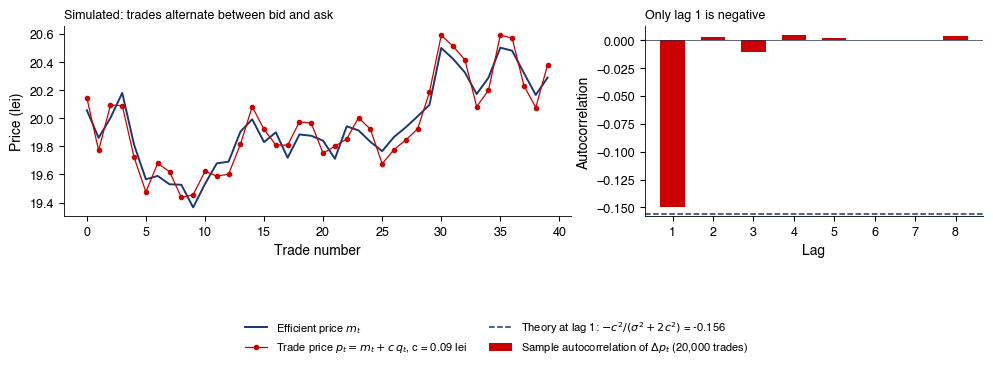

{'acf1': -0.150029822472831, 'rho': -0.15576923076923077}

In [7]:
# Rezolvare
def a1_roll(var=0.0520, cov=-0.0081, price=20.0, rho_q=0.3):
    """The Roll model: moments, the estimator and its bias when trade signs are autocorrelated.
    With Corr(q_t, q_{t-1}) = rho_q (Markov chain, m independent of q): Cov(dp_t, dp_{t-1}) = -c^2 (1 - rho_q)^2."""
    c = np.sqrt(-cov)
    cov_rho = -c ** 2 * (1 - rho_q) ** 2
    return dict(c=c, s=2 * c, s_pct=100 * 2 * c / price, sig2=var - 2 * c ** 2, share=2 * c ** 2 / var,
                rho=cov / var, var=var, cov=cov, price=price, rho_q=rho_q, cov_rho=cov_rho,
                c_roll_rho=np.sqrt(-cov_rho), bias_pct=100 * rho_q)


def fig_a1_bounce(c=0.09, sig2=0.0358, n_path=40, n_long=20000, seed=SEED):
    """A1 simulated: efficient price, trade price and autocorrelation of changes, with the parameters of A1 sub-task 2."""
    rng = np.random.default_rng(seed)
    m = 20 + np.cumsum(rng.normal(0, np.sqrt(sig2), n_long))
    q = np.where(rng.random(n_long) < 0.5, 1, -1)
    p = m + c * q
    dp = np.diff(p)
    dm = dp - dp.mean()
    acf = [float(np.mean(dm[k:] * dm[:-k]) / np.mean(dm ** 2)) for k in range(1, 9)]
    rho = -c ** 2 / (sig2 + 2 * c ** 2)
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), gridspec_kw=dict(width_ratios=[1.5, 1]))
    ax = axes[0]
    k = np.arange(n_path)
    ax.plot(k, m[:n_path], color=MainBlue, lw=1.4, label='Efficient price $m_t$')
    ax.plot(k, p[:n_path], color=IDAred, lw=0.9, marker='o', ms=3, label='Trade price $p_t = m_t + c\\,q_t$, c = 0.09 lei')
    ax.set_xlabel('Trade number')
    ax.set_ylabel('Price (lei)')
    ax.set_title('Simulated: trades alternate between bid and ask', fontsize=9, loc='left')
    ax = axes[1]
    lags = np.arange(1, 9)
    ax.bar(lags, acf, color=IDAred, width=0.6, label=f'Sample autocorrelation of $\\Delta p_t$ ({n_long:,} trades)')
    ax.axhline(rho, color=MainBlue, ls='--', lw=1.1, label=f'Theory at lag 1: $-c^2/(\\sigma^2 + 2c^2)$ = {rho:.3f}')
    ax.axhline(0, color=Gray, lw=0.5)
    ax.set_xlabel('Lag')
    ax.set_ylabel('Autocorrelation')
    ax.set_title('Only lag 1 is negative', fontsize=9, loc='left')
    h1, l1 = axes[0].get_legend_handles_labels()
    h2, l2 = axes[1].get_legend_handles_labels()
    fig_legend_bottom(fig, h1 + h2, l1 + l2, ncol=2, y=0.02)
    plt.tight_layout(rect=(0, 0.14, 1, 1))
    save_fig('ch10_sem_a1_bounce')
    return dict(acf1=acf[0], rho=rho)


a1_result = a1_roll()
a1_result['full_spread_with_correlated_signs'] = 2 * a1_result['c_roll_rho']
print(a1_result)
fig_a1_bounce()

c este jumătatea spreadului; s și full_spread_with_correlated_signs sînt spreaduri complete. Autocorelația pozitivă a semnelor tranzacțiilor reduce modulul covarianței la lag1, deci estimarea Roll necorectată este prea mică.

### A2. Precizia estimatorului Roll [Propus]
<a id="exercise-a2"></a>

- **Exemplu de urmat**: [A1](https://danpele.github.io/MFM/RO/Seminarii/seminar10_microstructura_pietei_ro.pdf#nameddest=ex-A1)

- **Întrebarea**: cît contează mărimea eșantionului $T$ pentru o singură estimare Roll, cu momentele populației fixate?

- **Date și ipoteze**

  - Momentele populației din [A1](https://danpele.github.io/MFM/RO/Seminarii/seminar10_microstructura_pietei_ro.pdf#nameddest=ex-A1): $\gamma_0 = 0{,}0520$, $\gamma_1 = -0{,}0081$, deci $c = 0{,}090$, $s = 0{,}18$ lei; estimatorul Roll $\hat s$ din [Autocovarianțele și modelul Roll](https://danpele.github.io/MFM/RO/Seminarii/seminar10_microstructura_pietei_ro.pdf#nameddest=sem10p3) [Harris (1990)](https://doi.org/10.1111/j.1540-6261.1990.tb03704.x)

  - $T$ = numărul variațiilor de preț din $T+1$ prețuri; dispersia Bartlett a lui $\hat\gamma_1$ și metoda delta: [Precizia estimatorului Roll](https://danpele.github.io/MFM/RO/Seminarii/seminar10_microstructura_pietei_ro.pdf#nameddest=sem10p4); $\Phi$: funcția de repartiție a distribuției Normale standard

<!-- -->

- **Cerințe**

  1.  Deduceți $g'(\gamma_1)$ pentru $g(\gamma_1) = 2\sqrt{-\gamma_1}$ și scrieți $\mathrm{se}(\hat s)$ prin metoda delta.

  2.  Completați tabelul de mai jos pentru $T = 78$ și $T = 250$ de variații de preț.

  3.  Aproximați $P(\hat\gamma_1 > 0)$ cu distribuția Normală centrată în covarianța populației, folosind eroarea standard Bartlett de la pasul 2; explicați sensul efectului centrării pe media eșantionului.

- **Raportați**: tabelul completat

- **Interpretare**: dacă modelul Roll este adevărat, cît de des am observa o covarianță pozitivă într-un eșantion de 78 de variații?



| $T$ | $\mathrm{se}(\hat\gamma_1)$ | $\mathrm{se}(\hat s)$ (lei) | $\mathrm{se}(\hat s)/s$ | $P(\hat\gamma_1 > 0)$ |
|:---|:--:|:--:|:--:|:--:|
| 78 | … | … | … | … |
| 250 | … | … | … | … |



[Exercise A2 in the seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar10_microstructura_pietei_ro.pdf#nameddest=ex-A2)

In [8]:
# Codul vostru aici


### A3. Glosten–Milgrom pentru orice probabilitate inițială [Rezolvat]
<a id="exercise-a3"></a>

- **Întrebările**

  - cît de larg este spread-ul cînd formatorul de piață învață din fluxul de ordine?

  - cînd este maxim?

- **Date și ipoteze**

  - $V \in \{V_L, V_H\}$, $\Delta V = V_H - V_L$; $\mathcal{F}_t$ = tranzacțiile observate pînă acum, $\theta = P(V = V_H \mid \mathcal{F}_t)$ [Glosten & Milgrom (1985)](https://doi.org/10.1016/0304-405X(85)90044-3)

  - Verosimilitățile: $P(\text{cump.} \mid V_H) = (1 + \mu)/2$, $P(\text{cump.} \mid V_L) = (1 - \mu)/2$ (ponderea investitorilor informați $\mu$; investitorii neinformați cumpără sau vînd cu probabilitatea 1/2)

  - Cotațiile înaintea următoarei tranzacții: $a = \mathbb{E}[V \mid \mathcal{F}_t, \text{cump.}]$, $b = \mathbb{E}[V \mid \mathcal{F}_t, \text{vînz.}]$; $V_L = 90$, $V_H = 110$, $\mu = 0{,}3$

<!-- -->

- **Cerințe**

  1.  La $\theta = 0{,}5$, calculați $P(V_H \mid \text{cump.})$, ask-ul, bid-ul și spread-ul.

  2.  După o cumpărare, probabilitatea a posteriori devine noul $\theta$: calculați cotațiile și spread-ul pentru tranzacția următoare.

  3.  Deduceți spread-ul pentru orice $0 < \theta < 1$ și arătați că este maxim la $\theta = 1/2$; verificați-l la $\theta = 0{,}7$.

  4.  Extindere: arătați că $\mathbb{E}[\text{prețul următoarei tranzacții} \mid \mathcal{F}_t] = \mathbb{E}[V \mid \mathcal{F}_t]$ și că probabilitățile formează un martingal.

- **Raportați**: cotațiile, formula spread-ului și argumentul de martingal

- **Interpretare**: de ce este spread-ul maxim cînd formatorul este cel mai nesigur?

- Pasul 1 ($\theta = 0{,}5$). $P(V_H \mid \text{cump.}) = 0{,}65 \cdot 0{,}5/(0{,}65 \cdot 0{,}5 + 0{,}35 \cdot 0{,}5) = 0{,}6500$: $a = 90 + 20 \cdot 0{,}6500 = 103{,}00$, $b = 97{,}00$, spread $6{,}00 = \mu\Delta V$

- Pasul 2. După o cumpărare $\theta = 0{,}6500$: $a = 105{,}50$, $b = 100{,}00$, spread $5{,}50$

- Pasul 3. Cu $x = 2\theta - 1$: $P(V_H \mid \text{cump.}) = \theta(1 + \mu)/(1 + \mu x)$, $P(V_H \mid \text{vînz.}) = \theta(1 - \mu)/(1 - \mu x)$

- Pasul 4. $a - b = \mu\Delta V(1 - x^2)/(1 - \mu^2x^2) \le \mu\Delta V$, cu egalitate doar la $x = 0$; la $\theta = 0{,}7$: 5,11

- Pasul 5. $P(\text{cump.})a + P(\text{vînz.})b = \mathbb{E}[V \mid \mathcal{F}_t]$ (așteptarea totală); așteptările iterate dau martingalul

- Interpretare: la $\theta = 1/2$ o tranzacție modifică cel mai mult probabilitățile estimate de formator, deci selecția adversă costă cel mai mult

[Exercise A3 in the seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar10_microstructura_pietei_ro.pdf#nameddest=ex-A3)

{'ask': 103.0, 'bid': 97.0, 'spread': 6.0, 'pb_h': 0.6499999999999999, 'pb_l': 0.35, 'th_b': 0.65, 'th_s': 0.35000000000000003, 'ask2': 105.5045871559633, 'bid2': 100.0, 'spread2': 5.504587155963307, 'th_b2': 0.7752293577981652, 'spread_07': 5.11363636363636, 'formula_07': 5.113636363636363, 'formula_05': 6.0}


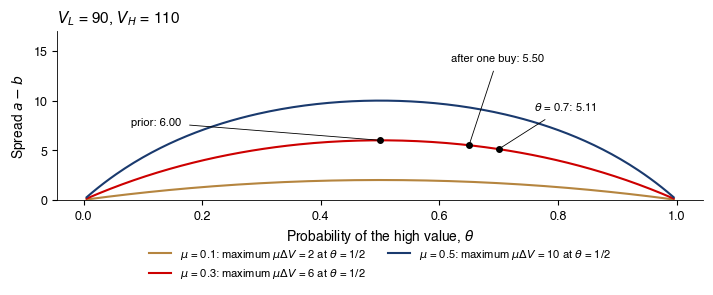

In [9]:
# Rezolvare
def gm_spread_formula(theta, mu, dv=20.0):
    """Glosten-Milgrom spread for general theta: a - b = 4 mu theta (1 - theta) dV / (1 - mu^2 (2 theta - 1)^2)."""
    return 4 * mu * theta * (1 - theta) * dv / (1 - mu ** 2 * (2 * theta - 1) ** 2)


def a3_gm(mu=0.3, theta=0.5, vl=90.0, vh=110.0):
    ask, bid, tb, ts = gm_quotes(theta, mu, vl, vh)
    ask2, bid2, tb2, ts2 = gm_quotes(tb, mu, vl, vh)          # after one buy
    a7, b7, _, _ = gm_quotes(0.7, mu, vl, vh)
    return dict(ask=ask, bid=bid, spread=ask - bid, pb_h=mu + (1 - mu) / 2, pb_l=(1 - mu) / 2, th_b=tb, th_s=ts,
                ask2=ask2, bid2=bid2, spread2=ask2 - bid2, th_b2=tb2, spread_07=a7 - b7,
                formula_07=gm_spread_formula(0.7, mu, vh - vl), formula_05=gm_spread_formula(0.5, mu, vh - vl))


def fig_a3_spread(dv=20.0):
    """A3: the Glosten-Milgrom spread as a function of the prior probability theta, for three shares mu."""
    th = np.linspace(0.005, 0.995, 200)
    fig, ax = plt.subplots(figsize=(7.2, 3.2))
    for mu, c in [(0.1, Amber), (0.3, IDAred), (0.5, MainBlue)]:
        ax.plot(th, gm_spread_formula(th, mu, dv), color=c, lw=1.5, label=f'$\\mu$ = {mu}: maximum $\\mu\\Delta V$ = {mu * dv:.0f} at $\\theta$ = 1/2')
    for t_, lab in [(0.5, 'prior'), (0.65, 'after one buy'), (0.7, '$\\theta$ = 0.7')]:
        v = gm_spread_formula(t_, 0.3, dv)
        ax.plot(t_, v, 'o', color='black', ms=4)
        ax.annotate(f'{lab}: {v:.2f}', (t_, v), xytext={0.5: (0.08, 7.5), 0.65: (0.62, 14), 0.7: (0.76, 9)}[t_], textcoords='data',
                    fontsize=8, color='black', bbox=dict(facecolor='white', edgecolor='none', alpha=0.9), arrowprops=dict(arrowstyle='-', lw=0.6))
    ax.set_xlabel('Probability of the high value, $\\theta$')
    ax.set_ylabel('Spread $a - b$')
    ax.set_ylim(0, 17)
    ax.set_title('$V_L$ = 90, $V_H$ = 110', loc='left')
    legend_outside_bottom(ax, ncol=2, y=-0.22)
    plt.tight_layout()
    save_fig('ch10_sem_a3_spread')


print(a3_gm())
fig_a3_spread()

Ask și bid condiționează pe direcții diferite ale tranzacției. Diferența compensează adverse selection; un prior echilibrat nu implică un spread nul.

### A4. Viteza de învățare a formatorului de piață [Propus]
<a id="exercise-a4"></a>

- **Exemplu de urmat**: [A3](https://danpele.github.io/MFM/RO/Seminarii/seminar10_microstructura_pietei_ro.pdf#nameddest=ex-A3)

- **Întrebările**

  - cîte cumpărări consecutive sînt necesare pînă cînd bid-ul depășește 108?

  - cum depinde acest număr de $\mu$?

- **Date și ipoteze**

  - [A3](https://danpele.github.io/MFM/RO/Seminarii/seminar10_microstructura_pietei_ro.pdf#nameddest=ex-A3) cu $\theta_0 = 1/2$, $V_L = 90$, $V_H = 110$; valoarea adevărată $V_H$; un **scenariu condiționat**: fiecare tranzacție este o cumpărare, nu timpul așteptat de învățare

  - Cronologia: după $k$ cumpărări probabilitatea este $\theta_k$; bid-ul cotat atunci se condiționează de o vînzare ipotetică următoare

<!-- -->

- **Cerințe**

  1.  Arătați că fiecare cumpărare înmulțește cota $\theta/(1 - \theta)$ cu $(1 + \mu)/(1 - \mu)$, iar fiecare vînzare o împarte la același factor.

  2.  Arătați că bid-ul după $k$ cumpărări este $V_L + \Delta V\,\theta_{k-1}$.

  3.  Arătați că bid $> 108$ cere o cotă peste 9, deduceți $k_{\min} = \lfloor \ln 9/\ln\frac{1 + \mu}{1 - \mu}\rfloor + 2$ ($\lfloor \cdot \rfloor$: partea întreagă) și evaluați-l pentru $\mu = 0{,}1; 0{,}3; 0{,}5$, verificînd cazul de la limită.

  4.  Comparați cu traiectoriile simulate din curs, în care investitorii neinformați pot și să vîndă.

- **Raportați**: cele trei valori ale lui $k_{\min}$ și graficul bid-ului în funcție de $k$

- **Interpretare**: cum depinde viteza descoperirii prețului de ponderea investitorilor informați?

[Exercise A4 in the seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar10_microstructura_pietei_ro.pdf#nameddest=ex-A4)

In [10]:
# Codul vostru aici


### A5. Deducerea echilibrului Kyle [Rezolvat]
<a id="exercise-a5"></a>

- **Întrebările**

  - cît de agresiv tranzacționează un investitor din interior?

  - cu cît mișcă formatorul prețul pe acțiune?

- **Date și ipoteze**

  - Cronologia: (1) investitorul vede $v \sim N(p_0, \sigma_v^2)$ și trimite $x$; (2) investitorii de zgomot trimit $u \sim N(0, \sigma_u^2)$, independent; (3) formatorul vede doar $y = x + u$ și stabilește $p = \mathbb{E}[v \mid y]$ [Kyle (1985)](https://doi.org/10.2307/1913210)

  - Unități: $v$, $p$ în USD; $x$, $u$, $y$ în acțiuni; $\beta$ în acțiuni per USD; $\lambda$ în USD per acțiune. Cifre: $\sigma_v = 2$, $\sigma_u = 10\,000$ și $20\,000$

<!-- -->

- **Cerințe**

  1.  Răspunsul optim al investitorului: dat $p = p_0 + \lambda y$, maximizați profitul așteptat și scrieți $\beta$ din $x = \beta(v - p_0)$.

  2.  Prețul formatorului: dat $x = \beta(v - p_0)$, deduceți $\lambda$ din teorema proiecției.

  3.  Rezolvați cele două ecuații; calculați profitul așteptat, $\operatorname{Var}(x)$ și $\operatorname{Var}(v \mid y)$.

  4.  Completați un tabel cu două coloane ($\sigma_u = 10\,000$ și $20\,000$): $\beta$, $\lambda$, profitul, variația prețului pentru $y = 15\,000$.

- **Raportați**: formulele echilibrului și tabelul

- **Interpretare**: de ce îl ajută mai mult zgomot pe investitorul din interior?

- Pasul 1. $\mathbb{E}[(v - p_0 - \lambda x - \lambda u)x \mid v] = (v - p_0)x - \lambda x^2$; condiția de ordinul întîi: $x = (v - p_0)/(2\lambda)$, $\beta = 1/(2\lambda)$

- Pasul 2. $(v, y)$ are distribuție Normală bivariată: $\lambda = \operatorname{Cov}(v, y)/\operatorname{Var}(y) = \beta\sigma_v^2/(\beta^2\sigma_v^2 + \sigma_u^2)$

- Pasul 3. Cu $2\lambda\beta = 1$: $\beta^2\sigma_v^2 = \sigma_u^2$, deci $\beta = \sigma_u/\sigma_v$, $\lambda = \sigma_v/(2\sigma_u)$

- Pasul 4. Profitul $\beta\sigma_v^2 - \lambda\beta^2\sigma_v^2 = \sigma_v\sigma_u/2$; $\operatorname{Var}(x) = \sigma_u^2$; $\operatorname{Var}(v \mid y) = \sigma_v^2/2$ în ambele economii

- Interpretare: $\lambda$ măsoară conținutul informațional per acțiune; mai mult zgomot face fluxul mai puțin informativ, investitorul tranzacționează mai mult și cîștigă mai mult, iar jumătate din informație intră totuși în preț



|  | $\sigma_u = 10^4$ | $\sigma_u = 2\cdot 10^4$ |
|:---|---:|---:|
| $\beta$ | 5 000 | 10 000 |
| $\lambda$ | 0,0001 | 0,00005 |
| profit (USD) | 10 000 | 20 000 |
| $\Delta p$ ($y = 15\,000$) | 1,50 | 0,75 |



[Exercise A5 in the seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar10_microstructura_pietei_ro.pdf#nameddest=ex-A5)

In [11]:
# Rezolvare
def a5_kyle(sigma_v=2.0, sigma_u=10_000.0, y=15_000.0, sigma_u2=20_000.0):
    k = kyle(sigma_v, sigma_u)
    k2 = kyle(sigma_v, sigma_u2)
    k.update(sigma_v=sigma_v, sigma_u=sigma_u, y=y, dp=k['lam'] * y, lam100=100 * k['lam'],
             lam2=k2['lam'], profit2=k2['profit'], beta2=k2['beta'])
    return k


kyle_result = a5_kyle()
kyle_result['dp2'] = kyle_result['lam2'] * kyle_result['y']
kyle_result['var_x'] = kyle_result['beta']**2 * kyle_result['sigma_v']**2
kyle_result['var_x2'] = kyle_result['beta2']**2 * kyle_result['sigma_v']**2
kyle_result

{'beta': 5000.0,
 'lam': 0.0001,
 'profit': 10000.0,
 'post_var': 2.0,
 'sigma_v': 2.0,
 'sigma_u': 10000.0,
 'y': 15000.0,
 'dp': 1.5,
 'lam100': 0.01,
 'lam2': 5e-05,
 'profit2': 20000.0,
 'beta2': 10000.0,
 'dp2': 0.75,
 'var_x': 100000000.0,
 'var_x2': 400000000.0}

lam este impactul pe acțiune; dp este schimbarea prețului pentru ordinul dat. Sufixul 2 indică volatilitatea dublă a cererii noise traders. var_x și var_x2 sînt varianțele ordinului informat, distincte de incertitudinea valorii după observarea ordinului (post_var).

### A6. Lambda lui Kyle ca pantă de regresie [Propus]
<a id="exercise-a6"></a>

- **Exemplu de urmat**: [A5](https://danpele.github.io/MFM/RO/Seminarii/seminar10_microstructura_pietei_ro.pdf#nameddest=ex-A5)

- **Întrebările**

  - ce estimează un raport de tip Amihud într-o economie Kyle?

  - contează alegerea volumului de la numitor?

- **Date și ipoteze**

  - [A5](https://danpele.github.io/MFM/RO/Seminarii/seminar10_microstructura_pietei_ro.pdf#nameddest=ex-A5) cu $p_0 = 50$ USD, $\sigma_v = 2$, $\sigma_u = 10\,000$; simulare (seed 42): 200 000 de licitații independente, $v = p_0 + \sigma_v z_1$, $u = \sigma_u z_2$, $x = \beta(v - p_0)$, $y = x + u$, $p = p_0 + \lambda y$, cu $z_1$, $z_2$ extrageri independente din distribuția Normală standard

  - $|x| + |u|$ este o aproximare a volumului brut de ordine (cele două ordine numărate separat), nu volumul bursei

<!-- -->

- **Cerințe**

  1.  Arătați că pantele Ordinary Least Squares (OLS) în populație ale lui $p - p_0$ și ale lui $v - p_0$ pe $y$ sînt ambele $\lambda$ și dați $\operatorname{Var}(y)$.

  2.  Arătați că $|r|/(p_0|y|)$, cu $r = (p - p_0)/p_0$, este $\lambda/p_0^2$ și convertiți-l în pb la 1 milion USD (factorul $10^4 \times 10^6$).

  3.  Înlocuiți $|y|$ cu $|x| + |u|$, deduceți sensul deplasării și măsurați-o prin simulare; repetați cu $\sigma_u = 20\,000$.

- **Raportați**: pantele, raportul pentru ambele numitoare și ambele niveluri de zgomot

- **Interpretare**

  - ce măsoară raportul Amihud în modelul Kyle?

  - de ce este deplasat cu volumul brut?

[Exercise A6 in the seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar10_microstructura_pietei_ro.pdf#nameddest=ex-A6)

In [12]:
# Codul vostru aici


### A7. Execuția Almgren–Chriss [Rezolvat]
<a id="exercise-a7"></a>

- **Întrebările**

  - cum ar trebui să împartă un vînzător cu aversiune la risc 1 milion de acțiuni pe cinci zile?

  - cît costă reducerea riscului?

- **Date și ipoteze**

  - Parametrii [Almgren & Chriss (2001)](https://doi.org/10.21314/JOR.2001.041): $X = 10^6$ acțiuni, $T = 5$ zile, $N = 5$, $\tau = 1$; $\sigma = 0{,}95$ USD pe zi$^{1/2}$; impactul temporar $\eta = 2{,}5 \cdot 10^{-6}$, permanent $\gamma = 2{,}5 \cdot 10^{-7}$ (USD pe acțiune per acțiune); aversiunea la risc $\lambda = 2 \cdot 10^{-6}$ per USD

  - $x_k$ = deținerea după tranzacția $k$ ($x_0 = X$, $x_5 = 0$), $n_k = x_{k-1} - x_k$; $\mathbb{E}[C] = \tfrac12\gamma X^2 + \frac{\tilde\eta}{\tau}\sum_{k=1}^{5} n_k^2$, $\operatorname{Var}[C] = \sigma^2\tau\sum_{k=1}^{5} x_k^2$, $\tilde\eta = \eta - \gamma\tau/2$

<!-- -->

- **Cerințe**

  1.  Calculați $\tilde\eta$, $\tilde\kappa^2 = \lambda\sigma^2/\tilde\eta$ și $\kappa$ din $\cosh(\kappa\tau) = 1 + \tilde\kappa^2\tau^2/2$.

  2.  Completați un tabel cu $k$, $x_k = X\sinh(\kappa(5 - k))/\sinh(5\kappa)$ și $n_k$.

  3.  Calculați $\mathbb{E}[C]$ și $\mathrm{sd}[C]$ și comparați cu vînzarea uniformă ($\lambda = 0$).

  4.  Extindere: minimizați $\int_0^T(\eta\dot x^2 + \lambda\sigma^2x^2)\,dt$ cu $x(0) = X$, $x(T) = 0$ prin Euler–Lagrange și comparați $\kappa_c$ cu $\kappa$.

- **Raportați**: tabelul programului, comparația cost–risc și graficul deținerilor

- **Interpretare**: ce obține investitorul în schimbul costului așteptat suplimentar?

- Pasul 1. $\tilde\eta = 2{,}5 \cdot 10^{-6} - 1{,}25 \cdot 10^{-7} = 2{,}375 \cdot 10^{-6}$; $\tilde\kappa^2 = 0{,}76$; $\cosh\kappa = 1{,}38$, $\kappa = 0{,}8463$, $\sinh(5\kappa) = 34{,}40$

- Pasul 2. Tabelul: 57% se vinde în prima zi

- Pasul 3. $\mathbb{E}[C] = 1{,}078$, $\mathrm{sd}[C] = 0{,}449$ milioane USD; uniform: 0,600 și 1,041

- Interpretare: vînzarea concentrată la început costă suplimentar 0,48 milioane USD impact așteptat pentru a reduce abaterea standard a costului la mai puțin de jumătate



| $k$ | $x_k$ | $n_k$ |
|-----------------------:|-----------------------:|-----------------------:|
|                      0 |              1 000 000 |                      – |
|                      1 |                428 599 |                571 401 |
|                      2 |                182 933 |                245 666 |
|                      3 |                 76 296 |                106 637 |
|                      4 |                 27 643 |                 48 652 |
|                      5 |                      0 |                 27 643 |







- $F = \eta\dot x^2 + \lambda\sigma^2x^2$: $\frac{d}{dt}\partial F/\partial\dot x = \partial F/\partial x \Rightarrow \ddot x = \kappa_c^2x$, $\kappa_c^2 = \lambda\sigma^2/\eta = 0{,}722$; cu $x(0) = X$, $x(T) = 0$: $x(t) = X\sinh(\kappa_c(T - t))/\sinh(\kappa_cT)$, $x(1) = 427\,151$

- $\kappa_c = 0{,}8497$ față de $\kappa = 0{,}8463$: apropiate aici fiindcă discretizarea și $\tilde\eta$ se compensează parțial ($\kappa\tau \approx 0{,}85$ nu este mic); punctele: programul discret, linia punctată: cel continuu

[Exercise A7 in the seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar10_microstructura_pietei_ro.pdf#nameddest=ex-A7)

{'lam': 2e-06, 'eta_t': 2.375e-06, 'kt2': 0.7599999999999999, 'kappa': np.float64(0.8462971345012561), 'kc': np.float64(0.84970583144992), 'kc2': np.float64(0.7219999999999998), 'x': [np.float64(1000000.0), np.float64(428598.8457470175), np.float64(182932.81426176784), np.float64(76295.7216154617), np.float64(27643.377396906417), np.float64(0.0)], 'xc': [np.float64(1000000.0), np.float64(427150.5440083748), np.float64(181711.71734401002), np.float64(75554.81028917071), np.float64(27310.618862276795), np.float64(0.0)], 'n': [np.float64(571401.1542529825), np.float64(245666.03148524964), np.float64(106637.09264630613), np.float64(48652.344218555285), np.float64(27643.377396906417)], 'E': np.float64(1078215.167049785), 'sd': np.float64(449367.65254135116), 'E0': np.float64(600000.0), 'sd0': np.float64(1040672.8592598157), 'sinh5': np.float64(34.402434282285846)}


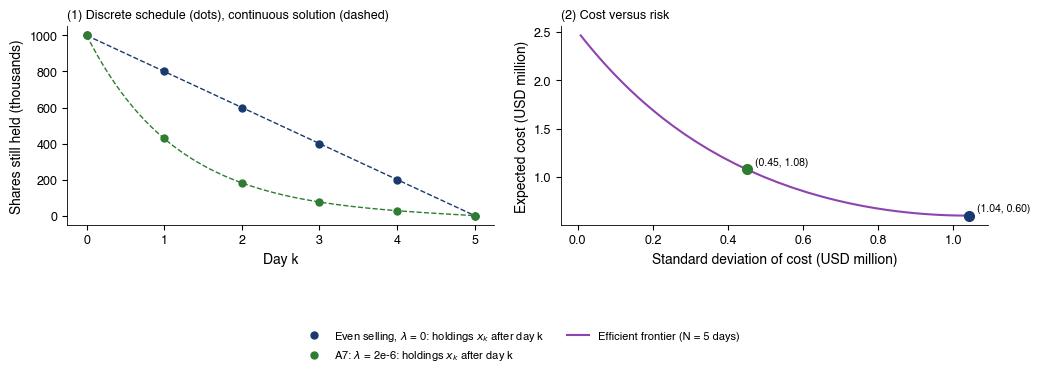

In [13]:
# Rezolvare
def a7_ac(lam=2e-6):
    """Almgren-Chriss: the continuous-time solution (Euler-Lagrange: x'' = kappa^2 x) and the exact discrete schedule."""
    tau = AC['T'] / AC['N']
    eta_t = AC['eta'] - AC['gamma'] * tau / 2
    kt2 = lam * AC['sigma'] ** 2 / eta_t
    kappa = np.arccosh(kt2 * tau ** 2 / 2 + 1) / tau
    kc = np.sqrt(lam * AC['sigma'] ** 2 / AC['eta'])          # continuous time: eta_tilde -> eta as tau -> 0
    t, x, E, V = ac_trajectory(lam=lam, **AC)
    t0, x0, E0, V0 = ac_trajectory(lam=0, **AC)
    xc = AC['X'] * np.sinh(kc * (AC['T'] - t)) / np.sinh(kc * AC['T'])
    return dict(lam=lam, eta_t=eta_t, kt2=kt2, kappa=kappa, kc=kc, kc2=kc ** 2, x=list(x), xc=list(xc),
                n=list(-np.diff(x)), E=E, sd=np.sqrt(V), E0=E0, sd0=np.sqrt(V0), sinh5=np.sinh(5 * kappa))

def fig_ac_seminar(public=True):
    """A7: holdings x_k after each day (discrete, N = 5) and the continuous solution; the cost - risk frontier."""
    fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.3))
    ax = axes[0]
    tt = np.linspace(0, AC['T'], 200)
    pts = {}
    for lam, c, lab in [(0, MainBlue, 'Even selling, $\\lambda$ = 0'), (2e-6, Forest, 'A7: $\\lambda$ = 2e-6')]:
        t, x, E, V = ac_trajectory(lam=lam, **AC)
        pts[lam] = (E, np.sqrt(V))
        ax.plot(t, x / 1e3, color=c, lw=0, marker='o', ms=5, label=lab + ': holdings $x_k$ after day k')
        if lam > 0:
            kc = np.sqrt(lam * AC['sigma'] ** 2 / AC['eta'])
            ax.plot(tt, AC['X'] * np.sinh(kc * (AC['T'] - tt)) / np.sinh(kc * AC['T']) / 1e3, color=c, lw=1, ls='--')
        else:
            ax.plot(tt, AC['X'] * (1 - tt / AC['T']) / 1e3, color=c, lw=1, ls='--')
    ax.set_xlabel('Day k')
    ax.set_ylabel('Shares still held (thousands)')
    ax.set_title('(1) Discrete schedule (dots), continuous solution (dashed)', fontsize=9, loc='left')
    ax = axes[1]
    fr = ac_frontier(lams=np.logspace(-8, -3.5, 60), **AC)
    ax.plot(fr['sd'] / 1e6, fr['E'] / 1e6, color=Purple, lw=1.5, label='Efficient frontier (N = 5 days)')
    for lam, c in [(0, MainBlue), (2e-6, Forest)]:
        E, sd = pts[lam]
        ax.plot(sd / 1e6, E / 1e6, 'o', color=c, ms=7)
        ax.annotate(f'({sd / 1e6:.2f}, {E / 1e6:.2f})', (sd / 1e6, E / 1e6), xytext=(6, 3), textcoords='offset points',
                    fontsize=7.5, color='black')
    ax.set_xlabel('Standard deviation of cost (USD million)')
    ax.set_ylabel('Expected cost (USD million)')
    ax.set_title('(2) Cost versus risk', fontsize=9, loc='left')
    h1, l1 = axes[0].get_legend_handles_labels()
    h2, l2 = axes[1].get_legend_handles_labels()
    fig_legend_bottom(fig, h1 + h2, l1 + l2, ncol=2, y=0.02)
    plt.tight_layout(rect=(0, 0.14, 1, 1))
    save_fig('ch10_sem_ac_public')


print(a7_ac())
fig_ac_seminar()

Citiți împreună media și abaterea standard a costului: aversiunea mai mare la risc mută lichidarea spre început, reduce expunerea la mișcările prețului și crește impactul temporar.

### A8. Un vînzător cu aversiune mai mare la risc [Propus]
<a id="exercise-a8"></a>

- **Exemplu de urmat**: [A7](https://danpele.github.io/MFM/RO/Seminarii/seminar10_microstructura_pietei_ro.pdf#nameddest=ex-A7); Repere de replicat: [valorile din curs](https://danpele.github.io/MFM/RO/Cursuri/capitol10_microstructura_pietei.pdf).

- **Întrebarea**: cum se schimbă programul cînd aversiunea la risc este de zece ori mai mare?

- **Date și ipoteze**

  - Parametrii din [A7](https://danpele.github.io/MFM/RO/Seminarii/seminar10_microstructura_pietei_ro.pdf#nameddest=ex-A7): $X = 10^6$, $T = N = 5$, $\sigma = 0{,}95$, $\eta = 2{,}5 \cdot 10^{-6}$, $\gamma = 2{,}5 \cdot 10^{-7}$; se schimbă doar $\lambda$, la $2 \cdot 10^{-5}$

<!-- -->

- **Cerințe**

  1.  Calculați $\tilde\kappa^2$, $\kappa$, $\kappa_c$ și deținerile $x_k$.

  2.  Calculați $\mathbb{E}[C]$ și $\mathrm{sd}[C]$ și rapoartele dintre noile valori și cele din [A7](https://danpele.github.io/MFM/RO/Seminarii/seminar10_microstructura_pietei_ro.pdf#nameddest=ex-A7), cu interpretarea lor.

  3.  Suprapuneți deținerile din [A7](https://danpele.github.io/MFM/RO/Seminarii/seminar10_microstructura_pietei_ro.pdf#nameddest=ex-A7) și [A8](https://danpele.github.io/MFM/RO/Seminarii/seminar10_microstructura_pietei_ro.pdf#nameddest=ex-A8) pe același grafic.

  4.  Opțional: explicați de ce $\kappa$ și $\kappa_c$ diferă acum mult mai mult.

- **Raportați**: un tabel de comparație și graficul

- **Interpretare**: cînd ar alege un investitor acest program?

[Exercise A8 in the seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar10_microstructura_pietei_ro.pdf#nameddest=ex-A8)

In [14]:
# Codul vostru aici


### A9. Verosimilitatea PIN, pas cu pas [Rezolvat]
<a id="exercise-a9"></a>

- **Întrebările**

  - cum evaluăm verosimilitatea unei zile de cumpărări și vînzări fără depășire numerică?

  - ce informație oferă ea despre acea zi?

- **Date și ipoteze**

  - Easley–Kiefer–O’Hara–Paperman (EKOP) [Easley et al. (1996)](https://doi.org/10.1111/j.1540-6261.1996.tb04074.x), trei stări: fără știri, prob. $1 - \alpha$, $(B, S) \sim$ Poisson$(\varepsilon_b)$, Poisson$(\varepsilon_s)$; știre proastă, $\alpha\delta$, vînzările cu intensitatea $\mu + \varepsilon_s$; știre bună, $\alpha(1 - \delta)$, cumpărările cu intensitatea $\mu + \varepsilon_b$

  - $\alpha = 0{,}3$, $\delta = 0{,}5$, $\mu = 400$, $\varepsilon_b = \varepsilon_s = 1\,000$; o zi cu $B = 1\,450$, $S = 1\,000$

<!-- -->

- **Cerințe**

  1.  Scrieți verosimilitatea ca amestec de trei componente și calculați $\mathrm{PIN} = \alpha\mu/(\alpha\mu + \varepsilon_b + \varepsilon_s)$.

  2.  Explicați de ce evaluarea directă a termenilor eșuează în dublă precizie.

  3.  Scrieți fiecare componentă logaritmică ponderată, combinați-le ca $m + \ln\sum e^{\ell_j - m}$ cu $m = \max_j \ell_j$ și normalizați aceleași componente în probabilități a posteriori.

- **Raportați**: PIN, $\ln L$, cele trei probabilități a posteriori

- **Interpretare**: este probabilitatea a posteriori a unei știri bune același lucru cu PIN?





- $\mathrm{PIN} = 120/2\,120 = 0{,}0566$; direct, $e^{-1\,000} \to 0$ și $1\,000^{1450} \to \infty$: $0 \cdot \infty$ = NaN [Lin & Ke (2011)](https://doi.org/10.1016/j.finmar.2011.03.001). Factorul $K = e^{-\varepsilon_b - \varepsilon_s}(\mu + \varepsilon_b)^B(\mu + \varepsilon_s)^S/(B!S!)$, $x_b = \varepsilon_b/(\mu + \varepsilon_b)$, $x_s$ la fel; $\ln B!$ prin log-gamma

- Componentele: $\ell_1 = \ln(1 - \alpha) + B\ln x_b + S\ln x_s$, $\ell_2 = \ln\alpha\delta - \mu + B\ln x_b$, $\ell_3 = \ln\alpha(1 - \delta) - \mu + S\ln x_s$; $\ln L = \ln K + m + \ln\sum e^{\ell_j - m} = -11{,}71$; a posteriori $e^{\ell_j - m}/\sum e^{\ell_i - m}$: știre bună $\approx$ 1

- Interpretare: 450 de cumpărări în plus față de o abatere standard Poisson de circa 32 clasifică ziua aproape sigur; PIN = 0,0566 este ponderea necondiționată așteptată a tranzacțiilor informate, nu această probabilitate a posteriori

[Exercise A9 in the seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar10_microstructura_pietei_ro.pdf#nameddest=ex-A9)

{'pin': 0.05660377358490566, 'naive': 'nan', 'exp_small': 0.0, 'loglik': -11.711088639429818, 'p_none': np.float64(3.1706463847436303e-38), 'p_bad': np.float64(1.7473662565978968e-66), 'p_good': np.float64(1.0), 'B': 1450, 'S': 1000, 'alpha': 0.3, 'delta': 0.5, 'mu': 400.0, 'eb': 1000.0, 'es': 1000.0}


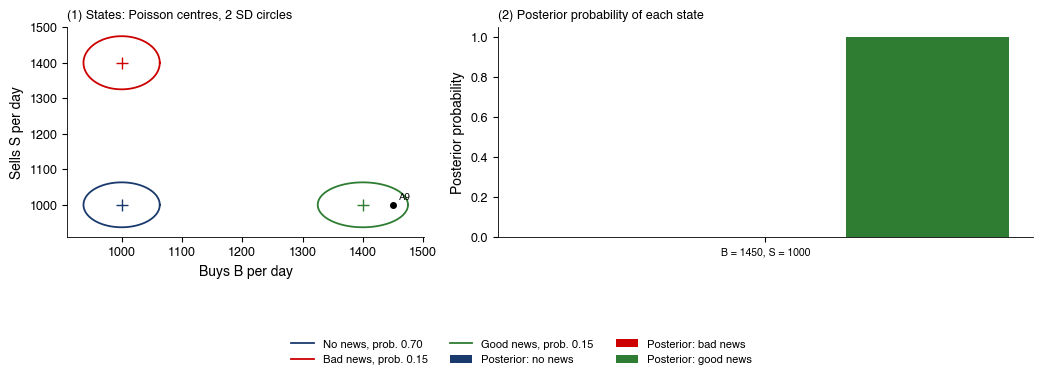

{'A9: B = 1450, S = 1000': [3.1706463847436303e-38,
  1.7473662565978968e-66,
  1.0]}

In [15]:
# Rezolvare
def pin_posterior(B, S, alpha, delta, mu, eb, es):
    """Posterior probabilities of the three states (no news, bad news, good news) given (B, S)."""
    from scipy.special import softmax
    _, terms = pin_loglik(B, S, alpha, delta, mu, eb, es)
    return softmax(terms)


def a9_pin(B=1450, S=1000, **par):
    """EKOP likelihood of one day: direct evaluation fails numerically, the factorised form does not."""
    import warnings as _w
    par = par or PIN_PAR
    a, d, mu, eb, es = (par[k] for k in ('alpha', 'delta', 'mu', 'eb', 'es'))
    pin = a * mu / (a * mu + eb + es)
    with _w.catch_warnings():
        _w.simplefilter('ignore')
        naive = np.exp(-eb) * np.float64(eb) ** B                 # e^-1000 = 0 and 1000^1450 = inf: 0 * inf = nan
    ll, _ = pin_loglik(B, S, a, d, mu, eb, es)
    post = pin_posterior(B, S, a, d, mu, eb, es)
    return dict(pin=pin, naive=str(naive), exp_small=float(np.exp(-eb)), loglik=ll, p_none=post[0], p_bad=post[1],
                p_good=post[2], B=B, S=S, **par)

def fig_pin(public=True, **par):
    """A9: the three states of the EKOP model (Poisson centres) and the posterior probabilities for the worked day."""
    days = PIN_DAYS[:1]
    par = par or PIN_PAR
    a, d_, mu, eb, es = (par[k] for k in ('alpha', 'delta', 'mu', 'eb', 'es'))
    fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.4), gridspec_kw=dict(width_ratios=[1, 1.5]))
    ax = axes[0]
    th = np.linspace(0, 2 * np.pi, 100)
    for (bx, sx), lab, c in [((eb, es), f'No news, prob. {1 - a:.2f}', MainBlue),
                             ((eb, es + mu), f'Bad news, prob. {a * d_:.2f}', IDAred),
                             ((eb + mu, es), f'Good news, prob. {a * (1 - d_):.2f}', Forest)]:
        ax.plot(bx + 2 * np.sqrt(bx) * np.cos(th), sx + 2 * np.sqrt(sx) * np.sin(th), color=c, lw=1.3, label=lab)
        ax.plot(bx, sx, '+', color=c, ms=8)
    for lab, B_, S_ in days:
        ax.plot(B_, S_, 'o', color='black', ms=4)
        ax.annotate(lab.split(':')[0], (B_, S_), xytext=(4, 4), textcoords='offset points', fontsize=7, color='black')
    ax.set_xlabel('Buys B per day')
    ax.set_ylabel('Sells S per day')
    ax.set_title('(1) States: Poisson centres, 2 SD circles', fontsize=9, loc='left')
    ax = axes[1]
    post = {}
    xs = np.arange(len(days))
    w = 0.26
    for j, (lab_, c) in enumerate([('No news', MainBlue), ('Bad news', IDAred), ('Good news', Forest)]):
        vals = []
        for lab, B_, S_ in days:
            pp = pin_posterior(B_, S_, a, d_, mu, eb, es)
            post[lab] = [float(v) for v in pp]
            vals.append(pp[j])
        ax.bar(xs + (j - 1) * w, vals, w, color=c, label=f'Posterior: {lab_.lower()}')
    ax.set_xticks(xs)
    ax.set_xticklabels([l.split(': ')[1] for l, _, _ in days], fontsize=7.5)
    ax.set_ylabel('Posterior probability')
    ax.set_title('(2) Posterior probability of each state', fontsize=9, loc='left')
    h1, l1 = axes[0].get_legend_handles_labels()
    h2, l2 = axes[1].get_legend_handles_labels()
    fig_legend_bottom(fig, h1 + h2, l1 + l2, ncol=3, y=0.02)
    plt.tight_layout(rect=(0, 0.13, 1, 1))
    save_fig('ch10_sem_pin_public')
    return post


print(a9_pin())
fig_pin()

PIN este o pondere necondiționată a tranzacțiilor informate. Probabilitățile posterioare condiționează pe numerele buy/sell ale zilei și răspund unei alte întrebări.

### A10. Citirea zilelor cu modelul PIN [Propus]
<a id="exercise-a10"></a>

- **Exemplu de urmat**: [A9](https://danpele.github.io/MFM/RO/Seminarii/seminar10_microstructura_pietei_ro.pdf#nameddest=ex-A9)

- **Întrebările**

  - cu ce grad de certitudine pot clasifica o zi parametrii PIN cunoscuți?

  - ce se schimbă cînd parametrii sînt necunoscuți?

- **Date și ipoteze**

  - Parametrii din [A9](https://danpele.github.io/MFM/RO/Seminarii/seminar10_microstructura_pietei_ro.pdf#nameddest=ex-A9); două zile observate (a) $B = 1\,000$, $S = 1\,420$; (b) $B = S = 1\,000$; (c) o zi ipotetică ambiguă, $B = 1\,195$, $S = 1\,000$

<!-- -->

- **Cerințe**

  1.  Pentru fiecare zi, calculați log-verosimilitatea stabilă și cele trei probabilități a posteriori.

  2.  Calculați PIN cînd $\mu$ se dublează la 800.

  3.  Conceptual: explicați de ce estimarea lui $(\alpha, \delta, \mu, \varepsilon_b, \varepsilon_s)$ din multe zile rămîne dificilă pentru acțiuni foarte lichide.

- **Raportați**: un tabel al zilelor cu probabilitățile a posteriori și noul PIN

- **Interpretare**: poate fi interpretat un dezechilibru al ordinelor întotdeauna ca semn de informație privată?

[Exercise A10 in the seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar10_microstructura_pietei_ro.pdf#nameddest=ex-A10)

In [16]:
# Codul vostru aici


## Partea B — estimare și inferență

### B1. Forma de U intrazilnică pentru SPY [Rezolvat]
<a id="exercise-b1"></a>

- **Întrebările**

  - sînt volatilitatea și volumul sistematic mai mari la deschidere și la închidere?

  - este tiparul determinat de cîteva zile extreme?

- **Date și ipoteze**

  - Barele SPY de 5 minute, 1 477 de zile complete (Datele folosite); $|r|$ în pb; barele sînt etichetate cu ora de început

  - Un rînd pe zi: $|r|$ al primei bare (09:30), media $|r|$ a celor 31 de bare de la prînz care încep între 11:30 și 14:00 inclusiv și ponderea volumului zilei în ultimele șase bare

<!-- -->

- **Cerințe**

  1.  Calculați raportul mediilor pe zile, $\overline{|r|}_{\text{deschidere}}/\overline{|r|}_{\text{prînz}}$, și ponderea medie a volumului din ultimele 30 de minute.

  2.  Construiți intervale bootstrap pe zile de 95% pentru ambele statistici (1 000 de reeșantionări ale rîndurilor complete, seed 42).

  3.  Reprezentați media $|r|$ și ponderea medie a volumului pe bare, cu benzi bootstrap punctuale pe zile.

- **Raportați**: cele două estimări cu intervale și cele două profile

- **Interpretare**

  - de ce reeșantionăm zile, nu bare?

  - ce implică tiparul pentru un investitor care trebuie să cumpere azi 1 milion de acțiuni?

- Pasul 1. Estimările punctuale: $\overline{|r|}_{\text{deschidere}} = 10{,}6$ pb, $\overline{|r|}_{\text{prînz}} = 5{,}1$ pb, raportul $2{,}06$; ultimele 30 de minute 18,6% din volumul zilnic, față de $6/78 = 7{,}7\%$ la o repartizare uniformă

- Pasul 2. O reeșantionare: extragem 1 477 de rînduri-zi cu întoarcere (aici apar 933 de zile distincte), păstrăm fiecare rînd întreg, recalculăm

  - Prima reeșantionare: 10,7 pb și 5,0 pb, raportul 2,13

- Pasul 3. Repetăm de 1 000 de ori; percentilele 2,5% și 97,5%: raportul $[1{,}98; 2{,}15]$, ponderea volumului $[18{,}3; 19{,}0]\%$

- Motivul reeșantionării zilelor întregi: barele unei zile au în comun volatilitatea și știrile ei, deci reeșantionarea zilelor păstrează această dependență; zilele sînt totuși tratate ca independente, deși volatilitatea persistă

- Ambele intervale sînt înguste și exclud reperele uniforme (raportul 1, 7,7%): un tipar sistematic, nu cîteva zile extreme; benzile sînt punctuale, nu o bandă simultană pentru toată curba

- Interpretare: un cumpărător mare găsește cel mai mult volum la deschidere și la închidere; deschiderea este însă și cea mai volatilă, deci momentul optim depinde și de spread-uri, impact, urgență și riscul așteptării

[Exercise B1 in the seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar10_microstructura_pietei_ro.pdf#nameddest=ex-B1)

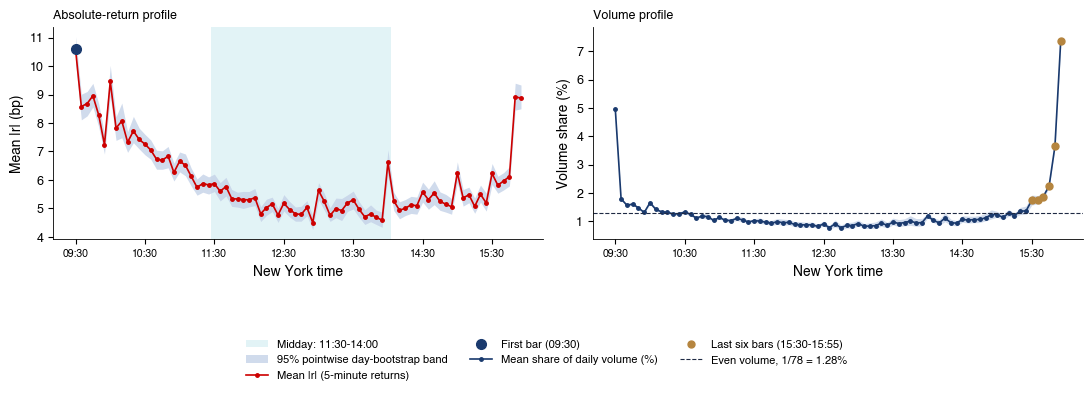

{'ratio': np.float64(2.0611100241206155),
 'lo': 1.9800262772534618,
 'hi': 2.154720227869524,
 'open': np.float64(10.590414985574784),
 'mid': np.float64(5.138209441338895),
 'vshare': np.float64(18.64671431741261),
 'vlo': 18.32366443924597,
 'vhi': 18.985597110968445,
 'n': 1477,
 'absr_close': 8.879817050739323,
 'n_mid_bars': 31,
 'first': {'ratio': 2.134893526465308,
  'n_unique': 933,
  'open': 10.685590593589126,
  'mid': 5.005210077750809,
  'vshare': 18.61406680509396}}

In [17]:
# Rezolvare
def b1_ushape():
    s = intraday_spy()
    x = s.dropna(subset=['r'])
    by_day = {}
    for d, g in x.groupby('date'):
        g = g.set_index('tod')
        by_day[d] = (abs(g['r'].get('09:30', np.nan)), g.loc['11:30':'14:00', 'r'].abs().mean(),
                     g['volume'].iloc[-6:].sum() / g['volume'].sum())
    arr = np.array(list(by_day.values()))
    ratio = np.nanmean(arr[:, 0]) / np.nanmean(arr[:, 1])
    lo, hi = boot_days(by_day, lambda v: np.nanmean([a[0] for a in v]) / np.nanmean([a[1] for a in v]))
    vs = np.nanmean(arr[:, 2])
    vlo, vhi = boot_days(by_day, lambda v: np.nanmean([a[2] for a in v]))
    tod = spy_tod(s)
    # one bootstrap step, explicitly: the first resample (same generator as boot_days)
    rng1 = np.random.default_rng(SEED)
    days = np.array(list(by_day.keys()))
    pick = rng1.choice(days, len(days), replace=True)
    a1 = np.array([by_day[d] for d in pick])
    first = dict(ratio=float(np.nanmean(a1[:, 0]) / np.nanmean(a1[:, 1])), n_unique=int(len(np.unique(pick))),
                 open=float(1e4 * np.nanmean(a1[:, 0])), mid=float(1e4 * np.nanmean(a1[:, 1])),
                 vshare=float(100 * np.nanmean(a1[:, 2])))
    # chart: mean |r| and share of the day's volume by interval, with pointwise day-bootstrap bands
    piv = x.pivot_table(index='date', columns='tod', values='r', aggfunc=lambda v: abs(v).mean())
    vsh = (s['volume'] / s.groupby('date')['volume'].transform('sum')).groupby([s['date'], s['tod']]).sum().unstack()
    rng = np.random.default_rng(SEED)
    bs = np.array([piv.iloc[rng.integers(0, len(piv), len(piv))].mean().values for _ in range(300)])
    lo_b, hi_b = 1e4 * np.nanpercentile(bs, 2.5, axis=0), 1e4 * np.nanpercentile(bs, 97.5, axis=0)
    rng = np.random.default_rng(SEED + 1)
    bv = np.array([vsh.iloc[rng.integers(0, len(vsh), len(vsh))].mean().values for _ in range(300)])
    lo_v, hi_v = 100 * np.percentile(bv, 2.5, axis=0), 100 * np.percentile(bv, 97.5, axis=0)
    k = np.arange(len(piv.columns))
    cols = list(piv.columns)
    i0, i1 = cols.index('11:30'), cols.index('14:00')
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
    ax = axes[0]
    ax.axvspan(i0 - 0.5, i1 + 0.5, color=Teal, alpha=0.12, lw=0, label='Midday: 11:30-14:00')
    ax.fill_between(k, lo_b, hi_b, color='#C5D2E8', alpha=0.8, lw=0, label='95% pointwise day-bootstrap band')
    ax.plot(k, 1e4 * piv.mean().values, color=IDAred, lw=1.2, marker='o', ms=2.5, label='Mean |r| (5-minute returns)')
    ax.plot(0, 1e4 * piv.mean().values[0], 'o', color=MainBlue, ms=7, label='First bar (09:30)')
    ax.set_xticks(k[::12])
    ax.set_xticklabels(cols[::12], fontsize=7.5)
    ax.set_xlabel('New York time')
    ax.set_ylabel('Mean |r| (bp)')
    ax.set_title('Absolute-return profile', fontsize=9, loc='left')
    ax = axes[1]
    ax.fill_between(k, lo_v, hi_v, color='#C5D2E8', alpha=0.8, lw=0)
    ax.plot(k, 100 * vsh.mean().values, color=MainBlue, lw=1.2, marker='o', ms=2.5, label='Mean share of daily volume (%)')
    ax.plot(k[-6:], 100 * vsh.mean().values[-6:], 'o', color=Amber, ms=5, label='Last six bars (15:30-15:55)')
    ax.axhline(100 / 78, color=Gray, lw=0.8, ls='--', label='Even volume, 1/78 = 1.28%')
    ax.set_xticks(k[::12])
    ax.set_xticklabels(cols[::12], fontsize=7.5)
    ax.set_xlabel('New York time')
    ax.set_ylabel('Volume share (%)')
    ax.set_title('Volume profile', fontsize=9, loc='left')
    h1, l1 = axes[0].get_legend_handles_labels()
    h2, l2 = axes[1].get_legend_handles_labels()
    fig_legend_bottom(fig, h1 + h2, l1 + l2, ncol=3, y=0.02)
    plt.tight_layout(rect=(0, 0.13, 1, 1))
    save_fig('ch10_sem_ushape')
    return dict(ratio=ratio, lo=lo, hi=hi, open=1e4 * np.nanmean(arr[:, 0]), mid=1e4 * np.nanmean(arr[:, 1]),
                vshare=100 * vs, vlo=100 * vlo, vhi=100 * vhi, n=len(by_day), absr_close=float(tod['absr'].iloc[-1]),
                n_mid_bars=int(i1 - i0 + 1), first=first)


b1_ushape()

Comparați volatilitatea și volumul după ora zilei. Forma U descrie momentul activității, fără să identifice singură cauza economică.

### B2. Estimatori de spread la două frecvențe [Rezolvat]
<a id="exercise-b2"></a>

- **Întrebarea**: ce frecvență de eșantionare conduce la un spread bid-ask credibil pentru SPY, cel mai tranzacționat Exchange-Traded Fund (ETF)?

- **Date și ipoteze**

  - Intrazilnic: cele 1 477 de zile de bare SPY de 5 minute; pe zi, 78 de închideri dau 77 de randamente logaritmice

  - Zilnic: bare SPY zilnice, 19 sep. 2024 – 18 sep. 2026 (501 zile); un pas = 0,01 USD. Roll zilnic folosește o singură autocovarianță de ordinul 1, centrată pe media întregii ferestre

- Rețetele (prețuri în logaritm; toate spread-urile relative)

  - Roll: pe zi, autocovarianța de ordinul 1 centrată pe medie a celor 77 de randamente, mediată pe zile, apoi $2\sqrt{-\bar\gamma_1}$, pusă la 0 dacă $\bar\gamma_1 \ge 0$ [Roll (1984)](https://doi.org/10.1111/j.1540-6261.1984.tb03897.x)

  - Corwin–Schultz: estimarea pe două bare pentru fiecare pereche de bare consecutive (negativele puse la 0), mediată; pentru barele zilnice se adaugă ajustarea pentru noapte [Corwin & Schultz (2012)](https://doi.org/10.1111/j.1540-6261.2012.01729.x)

  - Abdi–Ranaldo: media lui $4(c_t - \eta_t)(c_t - \eta_{t+1})$, apoi rădăcina pătrată, 0 dacă este negativă [Abdi & Ranaldo (2017)](https://doi.org/10.1093/rfs/hhx084)

- **Cerințe**

  1.  Calculați cei trei estimatori din barele de 5 minute, cu intervale bootstrap pe zile de 95% (reeșantionați rîndurile zilnice de momente deja calculate, nu prețurile).

  2.  Repetați pe aceeași fereastră de doi ani ca barele zilnice, astfel încît să difere doar frecvența.

  3.  Calculați cei trei estimatori din barele zilnice cu bootstrap pe blocuri mobile (blocuri de 20 de zile, 1 000 de reeșantionări) și raportați cît de des este trunchiat fiecare la 0.

  4.  Comparați fiecare estimare cu un pas raportat la preț, o limită inferioară pentru spread-ul cotat (nu pentru cel efectiv).

  5.  Simulați modelul Roll cu dispersia barelor SPY, 78 de prețuri pe zi, 1 477 de zile pe eșantion, 200 de eșantioane, pentru un spread de un tick ($c$ = jumătate de tick) și $c = 0$; calculați ponderea zilelor cu $\hat\gamma_1 > 0$ și estimarea agregată [Harris (1990)](https://doi.org/10.1111/j.1540-6261.1990.tb03704.x).

  6.  Corectați estimarea Roll agregată pe 5 minute pentru deplasarea din centrarea pe medie din [Precizia estimatorului Roll](https://danpele.github.io/MFM/RO/Seminarii/seminar10_microstructura_pietei_ro.pdf#nameddest=sem10p4), cu $T = 77$.

- **Raportați**: un grafic cu estimările și intervalele, ponderile trunchierii și rezultatele Monte Carlo lîngă cele observate

- **Interpretare**

  - ce frecvență dă un spread credibil?

  - ce măsoară estimatorii zilnici?

  - este ponderea covarianțelor pozitive o dovadă împotriva modelului Roll?

- 5 minute (2020–2026): Roll 2,82 $[2{,}09; 3{,}43]$, Corwin–Schultz 3,11 $[3{,}03; 3{,}20]$, Abdi–Ranaldo 1,06 $[0{,}00; 1{,}67]$ pb; aceiași doi ani (496 de zile): 1,95; 2,83; 0,00 pb

- Zilnic: Roll 64,3 $[0{,}0; 114{,}4]$, Corwin–Schultz 26,5 $[21{,}3; 33{,}7]$, Abdi–Ranaldo 55,1 $[0{,}0; 92{,}2]$ pb; trunchiat la 0 în 9,7% (Roll) și 3,4% (Abdi–Ranaldo) din reeșantionări; Abdi–Ranaldo pe 5 minute în 11,2%

- Un pas înseamnă 0,21 pb: estimările zilnice sînt cu două ordine de mărime peste el, fiindcă abaterea standard zilnică este 103,4 pb; chiar și estimarea Corwin–Schultz pe 5 minute reprezintă 15 pași

- Un pas: $c = 0{,}10$ pb, față de abaterea standard pe bară de 9,2 pb; ponderea zilelor pozitive 45,3% $[43{,}0; 48{,}1]$, cu $c = 0$ 45,3%: nu se deosebesc; observat 40,8%, sub ambele intervale de referință simulate

- Roll agregat: 2,07 pb (un pas), 2,06 pb ($c = 0$), observat 2,82 pb; corecția (formula deplasării rezolvată în raport cu $\gamma_1$, cu $T = 77$ și mediile pe zile $\bar\gamma_0$, $\bar\gamma_1$) $\hat\gamma_1^{c} = (\bar\gamma_1 + \bar\gamma_0/77)/(1 - 2/77)$ dă 1,92 pb

- Interpretare: doar barele intrazilnice dau ordine de mărime credibile; covarianțele pozitive sînt așteptate sub Roll, deci nu îl resping; autocorelația negativă rămasă indică presiune tranzitorie. Acestea sînt intervale de referință simulate, nu Confidence Interval (confidence interval (CI)) bootstrap

[Exercise B2 in the seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar10_microstructura_pietei_ro.pdf#nameddest=ex-B2)

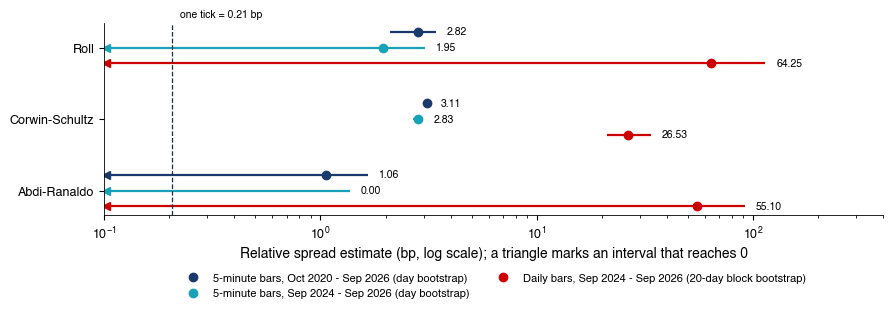

{'roll5': np.float64(2.8178694948515814),
 'rlo': 2.088525758122144,
 'rhi': 3.4255275546874655,
 'cs5': np.float64(3.114235796578178),
 'clo': 3.0289837140441427,
 'chi': 3.2013723971846377,
 'ar5': np.float64(1.0597709930490853),
 'alo': 0.0,
 'ahi': 1.667760884627947,
 'tick': np.float64(0.2065684865019977),
 'cs_d': np.float64(26.531990252599034),
 'cs_dlo': 21.267107513278532,
 'cs_dhi': 33.72329018189908,
 'ar_d': np.float64(55.09545779283073),
 'ar_dlo': 0.0,
 'ar_dhi': 92.17863018512608,
 'sd_daily': 103.3794289113439,
 'share_negcov': 0.5924170616113744,
 'roll_d': 64.25381258330147,
 'roll_dlo': 0.0,
 'roll_dhi': 114.43412214595969,
 'roll_d_pos': 0.097,
 'trunc_roll5': 0.0,
 'trunc_ar5': 0.112,
 'trunc_ar_d': 0.034,
 'trunc_roll_d': 0.097,
 'n_days5': 1477,
 'n_daily': 501,
 'n_ret5': 77,
 'n_days5m': 496,
 'roll5m': 1.947729143865,
 'cs5m': 2.8267272540140413,
 'ar5m': 0.0,
 'roll5mlo': 0.0,
 'roll5mhi': 3.0549445227034644,
 'cs5mlo': 2.6795327658870285,
 'cs5mhi': 2.972165

In [18]:
# Rezolvare
def b2_spreads():
    s = intraday_spy()
    E = intraday_spreads(s)
    by_day = {d: row for d, row in E.iterrows()}
    roll5 = 1e4 * 2 * np.sqrt(max(-E['cov'].mean(), 0))
    rlo, rhi = boot_days(by_day, lambda v: 1e4 * 2 * np.sqrt(max(-np.mean([r['cov'] for r in v]), 0)))
    cs5 = 1e4 * E['cs'].mean()
    clo, chi = boot_days(by_day, lambda v: 1e4 * np.mean([r['cs'] for r in v]))
    ar5 = 1e4 * np.sqrt(max(E['ar2'].mean(), 0))
    alo, ahi = boot_days(by_day, lambda v: 1e4 * np.sqrt(max(np.mean([r['ar2'] for r in v]), 0)))
    tick = 1e4 * (0.01 / E['price']).mean()
    # daily data: moving-block bootstrap with blocks of 20 days
    d = ohlc('SPY', START2)
    cs = cs_spread(d['high'], d['low'], d['close'])
    ar2 = ar_terms(d['close'], d['high'], d['low'])
    dp = np.diff(np.log(d['close'].values))
    pairs = np.column_stack([dp[1:], dp[:-1]])                # pairs (dp_t, dp_{t-1}) for the Roll covariance
    roll_cov = lambda x: np.mean(x[:, 0] * x[:, 1]) - x[:, 0].mean() * x[:, 1].mean()
    rng = np.random.default_rng(SEED)
    n, L = len(cs), 20
    csb, arb, rlb = [], [], []
    for _ in range(B):
        st = rng.integers(0, n - L + 1, n // L + 1)             # possible block starts: 0, ..., n - L
        idx = np.concatenate([np.arange(a, a + L) for a in st])[:n]
        csb.append(1e4 * cs[idx].mean())
        arb.append(1e4 * np.sqrt(max(ar2[idx].mean(), 0)))
        ip = np.minimum(idx, len(pairs) - 1)
        rlb.append(roll_cov(pairs[ip]))
    rlb = np.array(rlb)
    roll_d = 1e4 * 2 * np.sqrt(max(-roll_cov(pairs), 0))
    rlb_s = 1e4 * 2 * np.sqrt(np.maximum(-rlb, 0))
    sd_daily = 1e4 * np.log(d['close']).diff().std()
    res = dict(roll5=roll5, rlo=rlo, rhi=rhi, cs5=cs5, clo=clo, chi=chi, ar5=ar5, alo=alo, ahi=ahi, tick=tick,
               cs_d=1e4 * cs.mean(), cs_dlo=float(np.percentile(csb, 2.5)), cs_dhi=float(np.percentile(csb, 97.5)),
               ar_d=1e4 * np.sqrt(max(ar2.mean(), 0)), ar_dlo=float(np.percentile(arb, 2.5)),
               ar_dhi=float(np.percentile(arb, 97.5)), sd_daily=sd_daily, share_negcov=float((E['cov'] < 0).mean()),
               roll_d=float(roll_d), roll_dlo=float(np.percentile(rlb_s, 2.5)), roll_dhi=float(np.percentile(rlb_s, 97.5)),
               roll_d_pos=float((rlb >= 0).mean()))
    # how often each estimator is truncated at 0 across resamples (the averaged moment has the wrong sign)
    _, _, mc = boot_days(by_day, lambda v: np.mean([r['cov'] for r in v]), draws=True)
    _, _, ma = boot_days(by_day, lambda v: np.mean([r['ar2'] for r in v]), draws=True)
    res.update(trunc_roll5=float((mc >= 0).mean()), trunc_ar5=float((ma <= 0).mean()),
               trunc_ar_d=float((np.array(arb) == 0).mean()), trunc_roll_d=float((rlb >= 0).mean()),
               n_days5=int(len(E)), n_daily=int(len(d)), n_ret5=int(s.dropna(subset=['r']).groupby('date').size().iloc[0] - 1))
    # the same two-year window for the 5-minute bars (sensitivity: frequency without the period effect)
    Em = E.loc[START2:]
    bm = {dd: row for dd, row in Em.iterrows()}
    res.update(n_days5m=int(len(Em)),
               roll5m=float(1e4 * 2 * np.sqrt(max(-Em['cov'].mean(), 0))),
               cs5m=float(1e4 * Em['cs'].mean()), ar5m=float(1e4 * np.sqrt(max(Em['ar2'].mean(), 0))))
    res['roll5mlo'], res['roll5mhi'] = boot_days(bm, lambda v: 1e4 * 2 * np.sqrt(max(-np.mean([r['cov'] for r in v]), 0)))
    res['cs5mlo'], res['cs5mhi'] = boot_days(bm, lambda v: 1e4 * np.mean([r['cs'] for r in v]))
    res['ar5mlo'], res['ar5mhi'] = boot_days(bm, lambda v: 1e4 * np.sqrt(max(np.mean([r['ar2'] for r in v]), 0)))
    fig_b2_estimates(res)
    return res


b2_spreads()

Tabelul Monte Carlo separă probabilitatea unei covarianțe pozitive de distribuția spreadului trunchiat. O estimare nulă după trunchiere nu dovedește că tranzacționarea este gratuită.

{'pos_obs': 0.4075829383886256, 'n_days': 1477, 'sd_bar': 9.1583127862955, 'c_tick': 0.10328424325099884, 'pos_tick': 0.45316181448882875, 'pos_tick_lo': 0.4299255247122546, 'pos_tick_hi': 0.4808395396073122, 'roll_tick': 2.0730377581893937, 'roll_tick_lo': 1.5056679955636603, 'roll_tick_hi': 2.53365546070691, 'pos_zero': 0.4533243060257279, 'pos_zero_lo': 0.4312796208530806, 'pos_zero_hi': 0.4828199052132701, 'roll_zero': 2.0625393126665523, 'roll_zero_lo': 1.4988282803065303, 'roll_zero_hi': 2.526258631145369, 'roll_corr': 1.9180237793613462, 'roll5': 2.8178694948515814}


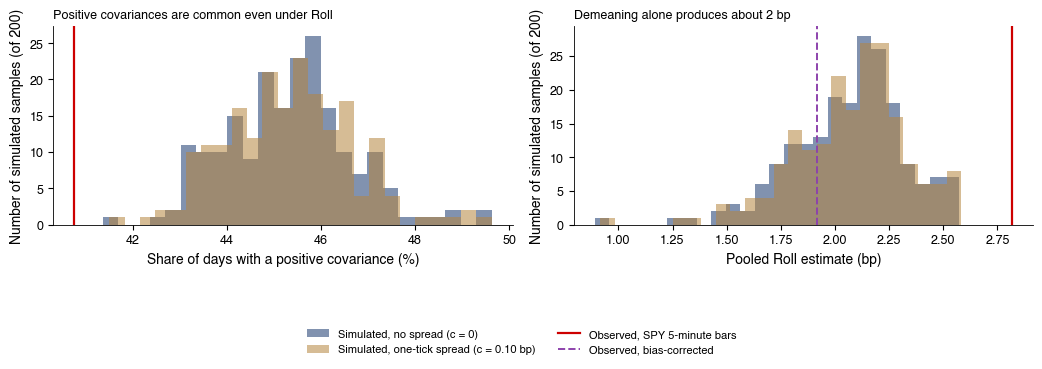

{'pos_tick': 0.45316181448882875,
 'pos_zero': 0.4533243060257279,
 'roll_tick': 2.0730377581893937,
 'roll_zero': 2.0625393126665523,
 'obs_pos': 0.4075829383886256,
 'obs_roll': 2.8178694948515814,
 'roll_corr': 1.9180237793613462,
 'var_bar': 8.387469309162364e-07,
 'n': 77,
 'n_days': 1477}

In [19]:
# Rezolvare, cerințele 5-6: Monte Carlo pentru modelul Roll (Harris, 1990)
spread_sample = intraday_spreads(intraday_spy())
print(roll_small_sample(spread_sample))


def b2_mc(E):
    """Monte Carlo under the Roll model, calibrated to SPY (same settings as roll_small_sample): distributions of the
    share of days with a positive covariance and of the pooled Roll estimate, for a one-tick spread and no spread."""
    n = 77
    v = E['var'].mean()
    c_tick = (0.01 / E['price']).mean() / 2
    obs_pos = float((E['cov'] > 0).mean())
    obs_roll = float(1e4 * 2 * np.sqrt(max(-E['cov'].mean(), 0)))
    g1 = (E['cov'].mean() + v / n) / (1 - 2 / n)
    corr = float(1e4 * 2 * np.sqrt(max(-g1, 0)))
    sims = {}
    for tag, c in [('tick', c_tick), ('zero', 0.0)]:
        sig = np.sqrt(v - 2 * c ** 2)
        cov = np.array([roll_mc(c, sig, T=n + 1, R=len(E), seed=SEED + b) for b in range(200)])
        sims[tag] = dict(pos=(cov > 0).mean(axis=1), pooled=1e4 * 2 * np.sqrt(np.clip(-cov.mean(axis=1), 0, None)))
    fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.3))
    for ax, key, xl, obs in [(axes[0], 'pos', 'Share of days with a positive covariance (%)', 100 * obs_pos),
                             (axes[1], 'pooled', 'Pooled Roll estimate (bp)', obs_roll)]:
        sc = 100 if key == 'pos' else 1
        for tag, c, lab in [('zero', MainBlue, 'Simulated, no spread (c = 0)'),
                            ('tick', Amber, f'Simulated, one-tick spread (c = {1e4 * c_tick:.2f} bp)')]:
            ax.hist(sc * sims[tag][key], bins=25, color=c, alpha=0.55, label=lab)
        ax.axvline(obs, color=IDAred, lw=1.6, label='Observed, SPY 5-minute bars')
        if key == 'pooled':
            ax.axvline(corr, color=Purple, lw=1.4, ls='--', label='Observed, bias-corrected')
        ax.set_xlabel(xl)
        ax.set_ylabel('Number of simulated samples (of 200)')
    axes[0].set_title('Positive covariances are common even under Roll', fontsize=9, loc='left')
    axes[1].set_title('Demeaning alone produces about 2 bp', fontsize=9, loc='left')
    h1, l1 = axes[0].get_legend_handles_labels()
    h2, l2 = axes[1].get_legend_handles_labels()
    fig_legend_bottom(fig, h1 + [h2[-1]], l1 + [l2[-1]], ncol=2, y=0.02)
    plt.tight_layout(rect=(0, 0.14, 1, 1))
    save_fig('ch10_sem_b2_mc')
    return dict(pos_tick=float(sims['tick']['pos'].mean()), pos_zero=float(sims['zero']['pos'].mean()),
                roll_tick=float(sims['tick']['pooled'].mean()), roll_zero=float(sims['zero']['pooled'].mean()),
                obs_pos=obs_pos, obs_roll=obs_roll, roll_corr=corr, var_bar=float(v), n=n, n_days=int(len(E)))


b2_mc(spread_sample)

pos_obs, pos_tick și pos_zero separă frecvența covarianțelor pozitive în date, în simularea cu tickuri și cu spread nul (c=0). Comparați roll5 cu roll_corr: corecția de centrare schimbă estimarea spread-ului, nu spread-ul observat direct.

### B3. Estimări ale spread-ului pentru 25 de active [Propus]
<a id="exercise-b3"></a>

- **Exemplu de urmat**: [B2](https://danpele.github.io/MFM/RO/Seminarii/seminar10_microstructura_pietei_ro.pdf#nameddest=ex-B2); Repere de replicat: [valorile din curs](https://danpele.github.io/MFM/RO/Cursuri/capitol10_microstructura_pietei.pdf).

- **Întrebările**

  - plasează aproximările zilnice ale spread-ului acțiunile BVB la același nivel de lichiditate cu cele americane?

  - confirmă raportul Amihud acest lucru?

- **Date și ipoteze**

  - Cele 25 de active de pe slide-ul Datele folosite: 7 SUA, 10 acțiuni BVB plus ETF-ul pe BET (11), 7 cripto; bare zilnice, 19 sep. 2024 – 18 sep. 2026

  - Estimatorii ca în [B2](https://danpele.github.io/MFM/RO/Seminarii/seminar10_microstructura_pietei_ro.pdf#nameddest=ex-B2) (rețetele zilnice); volatilitatea anualizată cu 252 de zile (acțiuni) sau 365 (cripto); Amihud în pb la 1 milion USD, volumul cripto deja în USD, BVB convertit la cursul BNR

<!-- -->

- **Cerințe**

  1.  Calculați Corwin–Schultz și Abdi–Ranaldo pentru fiecare activ și mediana fiecărui estimator pe grupuri.

  2.  Numărați, pe grupuri, activele pentru care Abdi–Ranaldo este pus la 0.

  3.  Calculați corelațiile Spearman ale Corwin–Schultz cu volatilitatea, ale Amihud cu valoarea tranzacționată mediană și ale Corwin–Schultz cu Amihud și desenați cele trei grafice de dispersie.

- **Raportați**: un tabel cu rîndurile SUA, BVB, cripto și coloanele mediana Corwin–Schultz, mediana Abdi–Ranaldo, zerourile Abdi–Ranaldo; cele trei corelații și grafice

- **Interpretare**

  - în ce indicator ați avea încredere pentru a compara piețele?

  - ce date v-ar trebui pentru validare?

[Exercise B3 in the seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar10_microstructura_pietei_ro.pdf#nameddest=ex-B3)

In [20]:
# Codul vostru aici


### B4. Ilichiditatea și Cboe Volatility Index (VIX) [Rezolvat]
<a id="exercise-b4"></a>

- **Întrebările**

  - cu cît crește ilichiditatea intrazilnică a SPY cînd crește volatilitatea implicită?

  - cît de precisă este elasticitatea?

- **Date și ipoteze**

  - $\mathrm{ILLIQ}_d = \frac{1}{78}\sum_{k} 10^4|r_{d,k}|/(\mathrm{DV}_{d,k}/10^8)$: pb la 100 de milioane USD, din barele de 5 minute ale zilei $d$, $k = 1, \dots, 78$ ($r_{d,k}$: randamentul logaritmic, $\mathrm{DV}_{d,k}$ = închiderea $\times$ volumul; $10^4$ convertește în pb, $10^8$ în 100 de milioane USD); barele cu valoare nulă eliminate

  - Seriile sînt aliniate pe zilele de tranzacționare cu închiderea indicelui VIX: 1 477 de zile, 2020-10-12 – 2026-09-18; media $\mathrm{ILLIQ}$ 1,83

- **Cerințe**

  1.  Estimați prin OLS $\ln\mathrm{ILLIQ}_d = a + b\ln\mathrm{VIX}_d + e_d$ (regresia log-log din [Regresia în logaritmi: elasticitatea și $R^2$](https://danpele.github.io/MFM/RO/Seminarii/seminar10_microstructura_pietei_ro.pdf#nameddest=sem10p10)) și desenați dreapta.

  2.  Desenați autocorelațiile reziduurilor; raportați erorile standard OLS și Heteroskedasticity and Autocorrelation Consistent (HAC) ([Erori HAC: dependența schimbă incertitudinea](https://danpele.github.io/MFM/RO/Seminarii/seminar10_microstructura_pietei_ro.pdf#nameddest=sem10p11), 20 de laguri) și intervalul HAC de 95% [Newey & West (1987)](https://doi.org/10.2307/1913610).

  3.  Extindere: adăugați o tendință liniară $t$ (în ani de la prima zi) și reestimați $b$.

  4.  Extindere: cu $D_d = 1$ de la 2023-09-27 (mijlocul eșantionului, fixat înainte de estimare), adăugați $gD_d + hD_d\ln\mathrm{VIX}_d$ și testați $h = 0$ cu testul Wald HAC din [O ruptură a pantei și testul Wald](https://danpele.github.io/MFM/RO/Seminarii/seminar10_microstructura_pietei_ro.pdf#nameddest=sem10p12) la 5%.

- **Raportați**: un tabel al specificațiilor ($\hat b$, Standard Error (SE), interval) și graficul coeficienților

- **Interpretare**

  - de ce diferă cele două erori standard?

  - este elasticitatea stabilă?

  - este relația cauzală?





- \(1\) $\hat b = 0{,}95$, $R^2 = 0{,}30$: un VIX mai mare cu 10% se asociază cu o ilichiditate mai mare cu circa $0{,}95 \times 10\%$; (2) autocorelația reziduurilor la lagul 1 0,76, care scade lent: SE OLS 0,038, SE HAC 0,121 (de 3,2 ori mai mare), CI HAC $[0{,}72; 1{,}19]$



| Specificația                | $\hat b$ |  SE   |  interval 95%  |
|:----------------------------|:----------------------:|:-----:|:--------------:|
| De bază, SE OLS             |          0,95          | 0,038 |       –        |
| De bază, SE HAC             |          0,95          | 0,121 | \[0,72; 1,19\] |
| Cu tendință (HAC)           |          0,80          | 0,120 |       –        |
| Înainte de 2023-09-27 (HAC) |          1,03          | 0,090 |       –        |
| De la 2023-09-27 (HAC)      |          0,60          | 0,238 |       –        |



- Tendința -0,062 pe an (SE 0,021): ilichiditatea scade în timp, legătura cu VIX rămîne; ruptura: $\hat h = -0{,}43$, Wald $(\hat h/\mathrm{SE})^2 = (-0{,}43/0{,}25)^2 = 2{,}90$, $p = 0{,}089$: nerespins la 5%

- Interpretare: reziduurile persistente fac erorile OLS mult prea mici; elasticitatea este aproape de 1; nerespingerea la 5% nu dovedește stabilitatea; relația nu este cauzală, fiindcă ambele reacționează la știri

[Exercise B4 in the seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar10_microstructura_pietei_ro.pdf#nameddest=ex-B4)

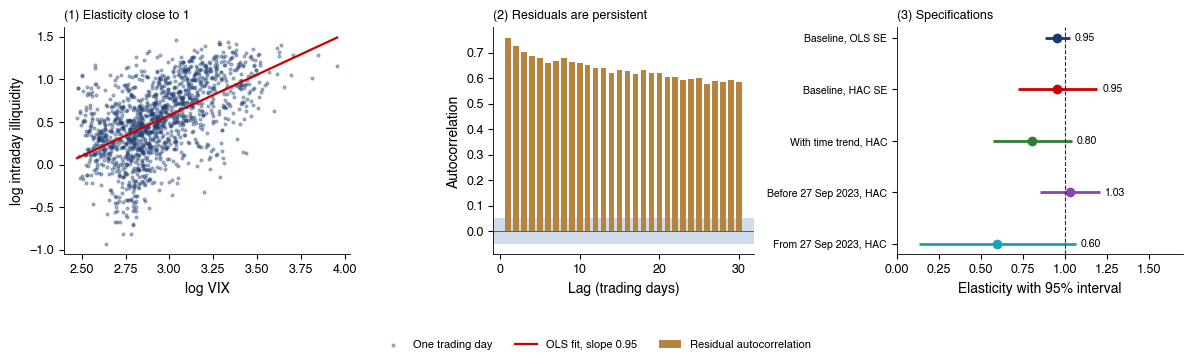

{'se_post': 0.23792780260621466,
 'wald': 2.8988116145613536,
 'se_pre': 0.08994005798972952,
 'a': -2.285283288165777,
 'illiq_mean': 1.8339556993864106,
 'vix_mean': 19.473276912660797,
 'start': '2020-10-12',
 'end': '2026-09-18',
 'b': 0.9544304059527832,
 'se_ols': 0.03762559414053015,
 'se_hac': 0.12116131927996482,
 'brk': '2023-09-27',
 'b_pre': 1.029337759489565,
 'b_post': 0.5962705134490079,
 'd_brk': -0.433067246040557,
 'se_brk': 0.25435796505618935,
 'p_brk': 0.08864488292106393,
 'lo': 0.7169542201640522,
 'hi': 1.1919065917415141,
 'r2': 0.30373962833787016,
 'n': 1477,
 'rho1': 0.7589592718584635,
 'b2': 0.8042733818184661,
 'se2': 0.12031769162600765,
 'trend': -0.0616845891503183,
 'se_trend': 0.021082133375156693}

In [21]:
# Rezolvare
def b4_illiq_vix():
    s = intraday_spy()
    ill = spy_illiq_daily(s)
    vix = read_market('VIX.INDX')['close'].rename('vix')
    j = pd.concat([ill, vix], axis=1, join='inner').dropna()
    y, X = np.log(j['illiq']), sm.add_constant(np.log(j['vix']))
    ols = sm.OLS(y, X).fit()
    hac = sm.OLS(y, X).fit(cov_type='HAC', cov_kwds={'maxlags': 20})
    # control for the level of traded value (trend)
    dvd = s.groupby('date')['dv'].sum().rename('dv')
    j2 = pd.concat([j, dvd], axis=1, join='inner').dropna()
    X2 = sm.add_constant(pd.DataFrame({'lvix': np.log(j2['vix']), 't': np.arange(len(j2)) / 252}))
    hac2 = sm.OLS(np.log(j2['illiq']), X2).fit(cov_type='HAC', cov_kwds={'maxlags': 20})
    rho1 = float(np.corrcoef(ols.resid[1:], ols.resid[:-1])[0, 1])
    # sub-task 4, elasticity stability: break at the middle of the sample (date fixed before estimation), HAC Wald test
    mid = j.index[len(j) // 2]
    post = (j.index >= mid).astype(float)
    X3 = sm.add_constant(pd.DataFrame({'lvix': np.log(j['vix']), 'post': post, 'lvix_post': post * np.log(j['vix'])},
                                      index=j.index))
    hac3 = sm.OLS(y, X3).fit(cov_type='HAC', cov_kwds={'maxlags': 20})
    w = hac3.wald_test('lvix_post = 0', scalar=True)
    cv3 = hac3.cov_params()
    se_post = float(np.sqrt(cv3.loc['lvix', 'lvix'] + cv3.loc['lvix_post', 'lvix_post'] + 2 * cv3.loc['lvix', 'lvix_post']))
    fig_b4(j, ols, hac, hac2, hac3, se_post, mid)
    return dict(se_post=se_post, wald=float(w.statistic), se_pre=float(hac3.bse['lvix']), a=float(hac.params.iloc[0]),
                illiq_mean=float(j['illiq'].mean()), vix_mean=float(j['vix'].mean()),
                start=j.index[0].strftime('%Y-%m-%d'), end=j.index[-1].strftime('%Y-%m-%d'), b=float(hac.params.iloc[1]), se_ols=float(ols.bse.iloc[1]), se_hac=float(hac.bse.iloc[1]),
                brk=mid.strftime('%Y-%m-%d'), b_pre=float(hac3.params['lvix']),
                b_post=float(hac3.params['lvix'] + hac3.params['lvix_post']), d_brk=float(hac3.params['lvix_post']),
                se_brk=float(hac3.bse['lvix_post']), p_brk=float(w.pvalue),
                lo=float(hac.params.iloc[1] - 1.96 * hac.bse.iloc[1]), hi=float(hac.params.iloc[1] + 1.96 * hac.bse.iloc[1]),
                r2=float(ols.rsquared), n=int(len(j)), rho1=rho1, b2=float(hac2.params['lvix']),
                se2=float(hac2.bse['lvix']), trend=float(hac2.params['t']), se_trend=float(hac2.bse['t']))


b4_illiq_vix()

Comparați coeficientul VIX între specificații și citiți intervalul lui. Testul de ruptură privește coeficientul interacțiunii, nu diferența vizuală dintre serii după dată.

### B5. Ilichiditatea Amihud pe trei piețe [Propus]
<a id="exercise-b5"></a>

- **Exemplu de urmat**: [B2](https://danpele.github.io/MFM/RO/Seminarii/seminar10_microstructura_pietei_ro.pdf#nameddest=ex-B2), [B3](https://danpele.github.io/MFM/RO/Seminarii/seminar10_microstructura_pietei_ro.pdf#nameddest=ex-B3); Repere de replicat: [valorile din curs](https://danpele.github.io/MFM/RO/Cursuri/capitol10_microstructura_pietei.pdf).

- **Întrebările**

  - de cîte ori este BVB mai puțin lichidă decît SUA după raportul Amihud?

  - cît de precis este multiplul?

  - cît de stabil este?

- **Date și ipoteze**

  - Cele 25 de active din [B3](https://danpele.github.io/MFM/RO/Seminarii/seminar10_microstructura_pietei_ro.pdf#nameddest=ex-B3) (BVB include ETF-ul pe BET); apartenența la grupuri fixă

  - Agregarea: mediem rapoartele zilnice pe fiecare activ, 19 sep. 2024 – 18 sep. 2026, apoi luăm mediana grupului

  - Anii: 19 sep. 2024 – 18 sep. 2025 și 19 sep. 2025 – 18 sep. 2026

<!-- -->

- **Cerințe**

  1.  Calculați cele trei mediane pe grupuri și raportul mediana BVB / mediana SUA.

  2.  Construiți un interval de 95% reeșantionînd activele cu întoarcere, independent în fiecare grup (1 000 de reeșantionări), recalculînd de fiecare dată raportul medianelor.

  3.  Calculați corelația Spearman a clasamentelor activelor în cei doi ani.

- **Raportați**: medianele, raportul cu intervalul lui, corelația de rang și grafice pe scală logaritmică

- **Interpretare**

  - de ce depinde intervalul?

  - este ilichiditatea o caracteristică stabilă a activului?

[Exercise B5 in the seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar10_microstructura_pietei_ro.pdf#nameddest=ex-B5)

In [22]:
# Codul vostru aici


### B6. Volum și mișcări de preț în barele SPY [Rezolvat]
<a id="exercise-b6"></a>

- **Întrebările**

  - cum crește randamentul absolut cu volumul relativ în barele de 5 minute?

  - poate fi interpretată panta ca lege a impactului?

- **Date și ipoteze**

  - Barele SPY de 5 minute cu volum pozitiv: 115 052 de bare în 1 477 de zile (115 206 bare minus 154 fără volum)

  - Volumul relativ $v$ = volumul barei / volumul median la aceeași oră; $z = |r|/\sigma_{\text{zi}}$, $\sigma_{\text{zi}}$ abaterea standard a randamentelor de 5 minute din acea zi

<!-- -->

- **Cerințe**

  1.  Împărțiți barele în 20 de grupe egale după $v$ (limitele fixate pe întregul eșantion), regresați $\ln\bar z$ pe $\ln\bar v$ ($\bar z$, $\bar v$: mediile pe grupe) și dați un interval bootstrap pe zile de 95% (300 de reeșantionări, aceleași limite).

  2.  La nivel de bară, estimați $\ln(|r| + 10^{-6}) - \ln\sigma_{\text{zi}} = a + b\ln v + e$ cu erori grupate pe zile, testați $b = 0{,}5$ și repetați fără barele cu $r = 0$.

  3.  Extindere: instrumentați $\ln v$ cu logaritmul volumului relativ al aceleiași bare din ziua de tranzacționare precedentă; raportați prima etapă și panta estimată prin Two-Stage Least Squares (2SLS, cele mai mici pătrate în două etape), cu SE grupată.

- **Raportați**: relația pe grupe, cele patru estimări ale pantei cu intervale și prima etapă

- **Interpretare**

  - este relația concavă?

  - este legea rădăcinii pătrate [Tóth et al. (2011)](https://doi.org/10.1103/PhysRevX.1.021006)?

  - este plauzibilă restricția de excludere?

- Panta pe grupe 0,274 $[0{,}262; 0{,}289]$; la nivel de bară 0,309 (SE 0,008), $t = (0{,}5 - 0{,}309)/0{,}008 \approx 24$: 0,5 respins; 0,8% din bare au $r = 0$, fără ele 0,291 (SE 0,008)

- Panta în prima etapă 0,339 ($t = 32{,}8$): instrument relevant; panta 2SLS 0,063 (SE 0,018); relevanța nu dovedește excluderea: volumul de ieri la acea oră reflectă activitatea persistentă și știrile programate (corelația cu lag a lui $\ln|r|$ normalizat 0,043)

- Interpretare: concavă, dar mai plată decît o rădăcină pătrată; o bară amestecă cumpărători și vînzători, iar legea privește metaordinul net al unui singur investitor, deci panta 0,5 nu o testează direct

[Exercise B6 in the seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar10_microstructura_pietei_ro.pdf#nameddest=ex-B6)

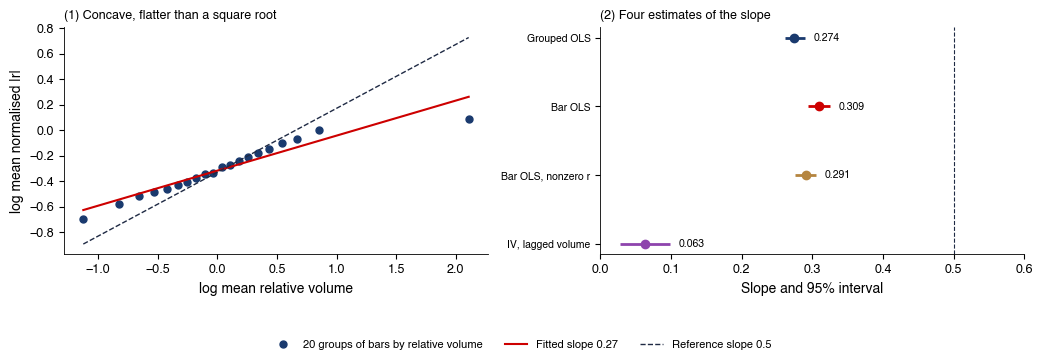

{'slope': 0.2741805378202134,
 'lo': 0.2615504642483289,
 'hi': 0.28929374285577375,
 'n': 115052,
 'n_days': 1477,
 'raw': 0.30916679954290216,
 'raw_se': 0.007894481991039768,
 'zero_share': 0.007683482251503615,
 'raw_nz': 0.29090810366111325,
 'raw_nz_se': 0.007614247781602145,
 'fs': 0.33892084364726316,
 'fs_t': 32.78652152889044,
 'iv': 0.06268299972220037,
 'iv_se': 0.01810321201506867,
 'n_iv': 114974,
 'corr_absr_lag': 0.0433724147607286,
 't_raw_slope_equals_half': -24.17298572264696}

In [23]:
# Rezolvare
def b6_sqrt():
    s = intraday_spy()
    x, g, slope, _ = sqrt_relation(s)
    days = x['date'].unique()
    by = {d: grp for d, grp in x.groupby('date')}
    bins = np.quantile(x['part'], np.linspace(0, 1, 21))
    rng = np.random.default_rng(SEED)
    sl = []
    for _ in range(300):
        pick = rng.choice(days, len(days), replace=True)
        xx = pd.concat([by[d] for d in pick])
        gg = xx.groupby(pd.cut(xx['part'], bins, include_lowest=True)).agg(v=('part', 'mean'), z=('z', 'mean')).dropna()
        sl.append(np.polyfit(np.log(gg['v']), np.log(gg['z']), 1)[0])
    lo, hi = np.percentile(sl, [2.5, 97.5])
    # on individual bars (not groups)
    y = np.log(x['r'].abs() + 1e-6) - np.log(x.groupby('date')['r'].transform('std'))
    raw = sm.OLS(y, sm.add_constant(np.log(x['part']))).fit(cov_type='cluster', cov_kwds={'groups': pd.factorize(x['date'])[0]})
    # zero returns: ln|r| is undefined; constant 1e-6 (0.01 bp) and, as a sensitivity check, dropping bars with r = 0
    nz = (x['r'] != 0).values
    raw_nz = sm.OLS(y[nz], sm.add_constant(np.log(x['part'][nz]))).fit(cov_type='cluster',
                                                                       cov_kwds={'groups': pd.factorize(x['date'][nz])[0]})
    # sub-task 3, instrumental variable: relative volume of the same bar (same time of day) on the previous day
    x = x.assign(ly=y, lv=np.log(x['part']))
    x['lv_lag'] = x.groupby('tod')['lv'].shift(1)             # bars are in time order; a shift within the time of day = the previous day
    x['ly_lag'] = x.groupby('tod')['ly'].shift(1)
    z = x.dropna(subset=['lv_lag', 'ly_lag'])
    gid = pd.factorize(z['date'])[0]
    fs = sm.OLS(z['lv'], sm.add_constant(z['lv_lag'])).fit(cov_type='cluster', cov_kwds={'groups': gid})
    Z = sm.add_constant(z['lv_lag']).values
    Xe = sm.add_constant(z['lv']).values
    Pz = Z @ np.linalg.solve(Z.T @ Z, Z.T @ Xe)               # projection of the regressors on the instruments
    b_iv = np.linalg.solve(Pz.T @ Xe, Pz.T @ z['ly'].values)
    e = z['ly'].values - Xe @ b_iv
    A = np.linalg.inv(Pz.T @ Pz)
    meat = sum(np.outer(Pz[gid == gg].T @ e[gid == gg], Pz[gid == gg].T @ e[gid == gg]) for gg in np.unique(gid))
    se_iv = np.sqrt(np.diag(A @ meat @ A))
    red = np.corrcoef(z['ly'], z['ly_lag'])[0, 1]            # yesterday's |r| at the same time: the channel that violates exclusion
    fig_b6(g, slope, (lo, hi), raw, raw_nz, b_iv[1], se_iv[1])
    return dict(slope=float(slope), lo=float(lo), hi=float(hi), n=int(len(x)), n_days=int(len(days)),
                raw=float(raw.params.iloc[1]), raw_se=float(raw.bse.iloc[1]), zero_share=float(1 - nz.mean()),
                raw_nz=float(raw_nz.params.iloc[1]), raw_nz_se=float(raw_nz.bse.iloc[1]), fs=float(fs.params.iloc[1]),
                fs_t=float(fs.tvalues.iloc[1]), iv=float(b_iv[1]), iv_se=float(se_iv[1]), n_iv=int(len(z)),
                corr_absr_lag=float(red))


sqrt_result = b6_sqrt()
sqrt_result['t_raw_slope_equals_half'] = (sqrt_result['raw'] - 0.5) / sqrt_result['raw_se']
sqrt_result

raw și raw_se descriu panta pe bare și eroarea standard clustered; t_raw_slope_equals_half testează reperul 0,5. Panta grupată folosește o altă agregare, iar instrumentul volum întîrziat cere justificarea excluderii.

### B7. Ceasul Bitcoin [Propus]
<a id="exercise-b7"></a>

- **Exemplu de urmat**: [B1](https://danpele.github.io/MFM/RO/Seminarii/seminar10_microstructura_pietei_ro.pdf#nameddest=ex-B1)

- **Întrebarea**: urmează o piață deschisă 24/7 programul piețelor tradiționale?

- **Date și ipoteze**

  - Bare Bitcoin de 5 minute, UTC, 749 de zile (535 lucrătoare, 214 de weekend); randamentele calculate peste bare lipsă sînt eliminate; acoperirea este incompletă: doar 106 zile au toate cele 288 de bare (minimum 26); toate zilele sînt păstrate

  - Ponderarea: întîi media $|r|$ a fiecărei zile într-o fereastră (orele $[h_1, h_2)$), apoi media pe zile; rapoartele sînt rapoarte ale acestor medii

<!-- -->

- **Cerințe**

  1.  În zilele lucrătoare, calculați media $|r|$ în 13:00–17:00 UTC și în 03:00–11:00 UTC și raportul lor, cu un interval bootstrap pe zile de 95%.

  2.  Calculați raportul zile lucrătoare / weekend al mediei $|r|$, cu un interval bootstrap pe zile de 95% (1 000 de reeșantionări, seed 42; extrageți zile întregi din eșantionul comun, deci numărul zilelor lucrătoare și de weekend poate varia).

  3.  Desenați cele două profile orare cu benzi bootstrap pe zile.

- **Raportați**: cele două rapoarte cu intervale și profilele

- **Interpretare**: ce informații despre spread, adîncime și volum ar fi necesare pentru o decizie de execuție, dincolo de volatilitate?

[Exercise B7 in the seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar10_microstructura_pietei_ro.pdf#nameddest=ex-B7)

In [24]:
# Codul vostru aici


### B8. Descoperirea prețului: ETF-ul pe BET și BET-TR [Rezolvat]
<a id="exercise-b8"></a>

- **Întrebările**

  - domină descoperirea prețului ETF-ul pe BET sau indicele BET-TR?

  - cît de siguri putem fi cu închideri zilnice?

- **Date și ipoteze**

  - Logaritmul închiderilor $y_t = (\ln P^{\mathrm{ETF}}_t, \ln P^{\mathrm{idx}}_t)'$ Patria-TVBETETF (zilele cu tranzacții) și BET-TR, zile comune 2024-09-19 – 2026-09-18, 493 de observații VECM; ETF-ul reinvestește dividendele; BET-TR nu se tranzacționează

  - VECM: $\Delta y_t = a_0 + \alpha z_{t-1} + \sum_{i=1}^{p}\Gamma_i\Delta y_{t-i} + e_t$, $z_{t-1} = \ln P^{\mathrm{ETF}}_{t-1} - \ln P^{\mathrm{idx}}_{t-1}$, $\operatorname{Var}(e_t) = \Omega$; constantă nerestricționată; $p$ laguri ale *diferențelor*, alese după Bayesian Information Criterion (BIC) între 1 și 10 [Johansen (1991)](https://doi.org/10.2307/2938278)

- **Cerințe**

  1.  Desenați prețurile rebazate și baza; testul trace Johansen (rangul unu nu stabilește singur $\beta = (1, -1)'$, impus aici).

  2.  Estimați VECM și testați $\alpha_{\mathrm{ETF}} = 0$ și $\alpha_{\mathrm{idx}} = 0$ la 5%.

  3.  Cu $\alpha_\perp = (-\alpha_{\mathrm{idx}}, \alpha_{\mathrm{ETF}})'$ calculați ponderea componentei $\alpha_\perp/\sum\alpha_\perp$ [Gonzalo & Granger (1995)](https://doi.org/10.1080/07350015.1995.10524576) și ponderea informațională $([\alpha_\perp' F]_j)^2/\alpha_\perp'\Omega\alpha_\perp$ pentru ambele ordonări Cholesky, cu $F$ factorul inferior triunghiular, $FF' = \Omega$, și $[\cdot]_j$ elementul $j$ [Hasbrouck (1995)](https://doi.org/10.1111/j.1540-6261.1995.tb04054.x).

  4.  Bootstrap: reeșantionați blocuri mobile de 20 de rînduri ale regresiei $(\Delta y_t, 1, z_{t-1}, \Delta y_{t-1}, \ldots)$, de 1 000 de ori; apoi reestimați $\alpha$ pe fiecare jumătate.

- **Raportați**: testul, $\alpha$ cu intervale asimptotice și bootstrap, limitele de ordonare cu intervalele capetelor, cele două jumătăți

- **Interpretare**

  - care preț domină descoperirea prețului?

  - de ce sînt limitele largi?

  - de ce poate ponderea componentei să iasă din $[0, 1]$?





- BIC: 1 lag; trace 49,6 pentru $r = 0$ (valoarea critică 5% 15,49), 0,10 pentru $r \le 1$ (3,84): un vector de cointegrare

- $\alpha_{\mathrm{ETF}} = -0{,}12$ ($t = -2{,}11$, respins la 5%), $\alpha_{\mathrm{idx}} = -0{,}03$ ($t = -0{,}63$); bootstrap pe blocuri: ETF $[-0{,}29; 0{,}01]$, indice $[-0{,}18; 0{,}09]$: testul asimptotic respinge, intervalul bootstrap atinge 0, deci dovada este slabă

- Ponderea informațională a indicelui în $[0{,}25; 0{,}98]$ (limite de ordonare, nu CI); CI bootstrap pentru limita inferioară $[0{,}00; 0{,}64]$, pentru cea superioară $[0{,}72; 1{,}00]$; ponderea componentei 1,39 $[-0{,}14; 3{,}32]$

- Jumătățile: ETF $\alpha = -0{,}26$ ($t = -2{,}34$), apoi -0,09 ($t = -0{,}85$); indicele nu este niciodată semnificativ ($t = -0{,}77$, 0,47)

- Interpretare: ETF-ul pare să se ajusteze spre indice; corelația reziduurilor 0,93 face ordonarea decisivă, de aici limitele largi; ambii $\alpha$ negativi împing ponderea componentei în afara $[0, 1]$

[Exercise B8 in the seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar10_microstructura_pietei_ro.pdf#nameddest=ex-B8)

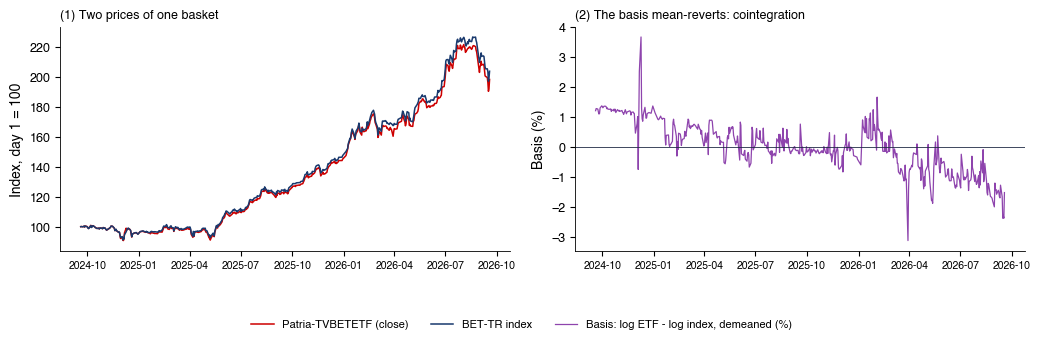

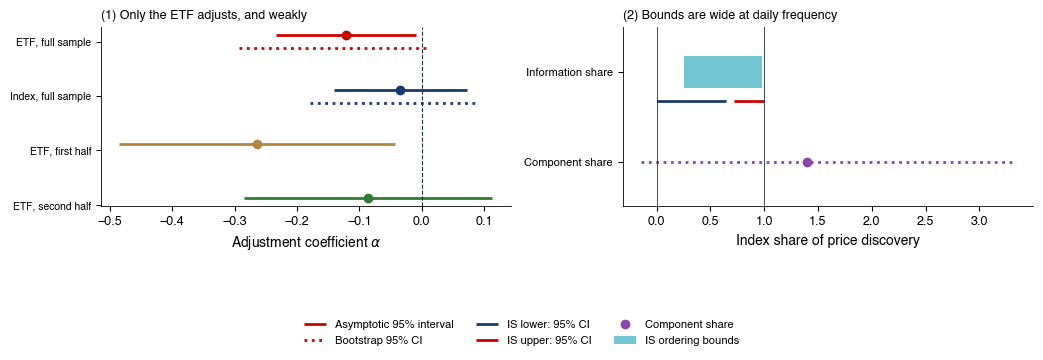

{'basis_mean': -724.4047423170958,
 'start': '2024-09-19',
 'end': '2026-09-18',
 'a_etf': -0.1214459102853011,
 'a_idx': -0.03428253008476459,
 't_etf': -2.1099805086951555,
 't_idx': -0.6336008319602243,
 'cs_idx': 1.393313453492635,
 'is_idx_lo': 0.2506303205818098,
 'is_idx_hi': 0.9774000124240595,
 'ci_a_etf': [-0.2935454011727737, 0.007610469736294262],
 'ci_a_idx': [-0.1789257458495205, 0.09119011636201929],
 'ci_cs_idx': [-0.14056426366042757, 3.324003541257161],
 'ci_is_lo': [0.00469437465834641, 0.6447464238224223],
 'ci_is_hi': [0.7202862311171911, 0.9997726639789694],
 'h1_a_etf': -0.2634961102572369,
 'h1_t_etf': -2.337134654848788,
 'h2_a_etf': -0.08606647810627799,
 'h2_t_etf': -0.8475282523918808,
 'h1_a_idx': -0.08448869371042537,
 'h2_a_idx': 0.04385152411372403,
 'h1_t_idx': -0.7690845357633991,
 'h2_t_idx': 0.4748021918555294,
 'corr': 0.9310847008895238,
 'n': 493,
 'p': 1,
 'trace': 49.638335176116335,
 'cv': 15.4943,
 'trace1': 0.10180446807762619,
 'cv1': 3.8415

In [25]:
# Rezolvare
def b8_price_discovery(B=B, L=20, seed=SEED):
    """The Patria-TVBETETF and the BET-TR index: VECM with the vector (1, -1), Hasbrouck share bounds, the
    Gonzalo-Granger share; moving-block bootstrap intervals (blocks of L days) over the VECM pairs (X_t, Y_t);
    then the two halves of the sample."""
    from statsmodels.tsa.vector_ar.vecm import coint_johansen, select_order
    y = bet_etf_pair().values
    p = max(int(select_order(y, maxlags=10, deterministic='co').bic), 1)   # BIC over 1..10 lags of dy
    jo = coint_johansen(y, 0, p)                                           # unrestricted constant
    base = price_discovery(y, p)
    dy = np.diff(y, axis=0)
    z = (y[:, 0] - y[:, 1])[:-1]
    X = np.array([[1.0, z[t]] + [v for i in range(1, p + 1) for v in dy[t - i]] for t in range(p, len(dy))])
    Y = dy[p:]
    rng = np.random.default_rng(seed)
    n = len(Y)
    draws = []
    for _ in range(B):
        st = rng.integers(0, n - L + 1, n // L + 1)
        idx = np.concatenate([np.arange(a, a + L) for a in st])[:n]
        Xb, Yb = X[idx], Y[idx]
        Bb = np.linalg.lstsq(Xb, Yb, rcond=None)[0]
        U = Yb - Xb @ Bb
        Om = U.T @ U / (n - X.shape[1])
        al = Bb[1]
        ap = np.array([-al[1], al[0]])
        ISs = []
        for order in ([0, 1], [1, 0]):
            F = np.linalg.cholesky(Om[np.ix_(order, order)])
            v = (ap[order] @ F) ** 2 / (ap @ Om @ ap)
            ISs.append(v[np.argsort(order)][1])
        draws.append((al[0], al[1], ap[1] / ap.sum(), min(ISs), max(ISs)))
    d = np.array(draws)
    ci = lambda k: [float(x) for x in np.percentile(d[:, k], [2.5, 97.5])]
    half = len(y) // 2
    h1, h2 = price_discovery(y[:half], p), price_discovery(y[half:], p)
    fig_b8(bet_etf_pair(), base, d, h1, h2)
    return dict(basis_mean=float(100 * np.mean(y[:, 0] - y[:, 1])), start=bet_etf_pair().index[0].strftime('%Y-%m-%d'),
                end=bet_etf_pair().index[-1].strftime('%Y-%m-%d'), a_etf=float(base['alpha'][0]), a_idx=float(base['alpha'][1]), t_etf=float(base['t'][0]),
                t_idx=float(base['t'][1]), cs_idx=float(base['cs'][1]), is_idx_lo=float(base['is_lo'][1]),
                is_idx_hi=float(base['is_hi'][1]), ci_a_etf=ci(0), ci_a_idx=ci(1), ci_cs_idx=ci(2), ci_is_lo=ci(3),
                ci_is_hi=ci(4), h1_a_etf=float(h1['alpha'][0]), h1_t_etf=float(h1['t'][0]), h2_a_etf=float(h2['alpha'][0]),
                h2_t_etf=float(h2['t'][0]), h1_a_idx=float(h1['alpha'][1]), h2_a_idx=float(h2['alpha'][1]),
                h1_t_idx=float(h1['t'][1]), h2_t_idx=float(h2['t'][1]), corr=base['corr'], n=int(base['n']), p=p,
                trace=float(jo.lr1[0]), cv=float(jo.cvt[0, 1]), trace1=float(jo.lr1[1]), cv1=float(jo.cvt[1, 1]))


b8_price_discovery()

basis_mean este o diferență de nivel dependentă de scară. Nu reprezintă direct un randament de arbitraj între prețul ETF și nivelul indicelui. Coeficienții lead/lag descriu ordinea predictivă, cu controalele precizate.

## Partea C — idei de proiect și critica unui răspuns Artificial Intelligence (AI)

### C2. Prima de ilichiditate pe BVB [Propus]
<a id="exercise-c2"></a>

- **Exemplu de urmat**: [B4](https://danpele.github.io/MFM/RO/Seminarii/seminar10_microstructura_pietei_ro.pdf#nameddest=ex-B4), [B5](https://danpele.github.io/MFM/RO/Seminarii/seminar10_microstructura_pietei_ro.pdf#nameddest=ex-B5); Repere de replicat: [valorile din curs](https://danpele.github.io/MFM/RO/Cursuri/capitol10_microstructura_pietei.pdf).

- **Întrebările**: Amihud (2002) prezice că ilichiditatea se reflectă în randamente [Amihud (2002)](https://doi.org/10.1016/S1386-4181(01)00024-6)

  - crește ilichiditatea așteptată randamentele viitoare pe BVB?

  - scade o creștere neașteptată a ilichidității randamentele curente?

- **Date și ipoteze**

  - Piețe: BVB (randament BET-TR; ilichiditatea din cele zece blue-chips), SUA (SPY; șase acțiuni americane), cripto (Bitcoin; alte șase monede); randamente logaritmice lunare în %, 2016–2026

  - Indicele: media rapoartelor Amihud pe activ și lună ($\ge 10$ zile); media transversală a logaritmului, $L_t$; șocul: reziduul modelului Autoregressive de ordinul 1 (AR(1)) $L_t = \phi_0 + \phi L_{t-1} + v_t$, cu $\hat\phi$ persistența estimată și $T$ numărul de luni

- **Cerințe**

  1.  Etapa 1: construiți indicele și șocul pentru fiecare piață.

  2.  Etapa 2: estimați $r_t = a + b_1 L_{t-1} + b_2\,\mathrm{șoc}_t + e_t$ cu SE HAC (6 laguri); $r_t$: randamentul lunar al pieței; Amihud prezice $b_1 > 0$ (ilichiditatea așteptată este remunerată) și $b_2 < 0$ (un șoc de ilichiditate scade prețurile).

  3.  Etapa 3: corectați $b_1$ pentru deplasarea Stambaugh [Stambaugh (1999)](https://doi.org/10.1016/S0304-405X(99)00041-0) (deplasarea lui $\hat b_1$ în eșantioane mici, cînd $L_t$ este persistent și șocurile lui sînt corelate cu randamentele) cu estimatorul cu deplasare redusă: $\hat\phi_c = \hat\phi + (1 + 3\hat\phi)/T + 3(1 + 3\hat\phi)/T^2$, reziduurile $v^c_t$ din $\hat\phi_c$, regresăm $r_t$ pe $L_{t-1}$ și $v^c_t$, cu SE care include incertitudinea lui $\hat\phi_c$ [Amihud & Hurvich (2004)](https://doi.org/10.1017/S0022109000003227).

  4.  Etapa 4 (sortări): în fiecare ianuarie ordonați blue-chips cu peste 150 de zile de tranzacționare după Amihud din anul anterior; dețineți jumătățile nelichidă și lichidă ponderate egal pe tot anul (randamente lunare simple totale); testați diferența medie cu SE HAC.

- **Raportați**: un tabel pe piețe, graficele de referință și o discuție despre putere (puține acțiuni, zece ani) [Pele, Mazurencu-Marinescu & Nijkamp (2013)](https://doi.org/10.2139/ssrn.2305945)

- **Interpretare**: care dintre cele două predicții ale lui Amihud este confirmată pe fiecare piață?

[Exercise C2 in the seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar10_microstructura_pietei_ro.pdf#nameddest=ex-C2)

Convențiile eșantionului și erorilor standard: [C2 data](https://danpele.github.io/MFM/EN/Seminars/seminar10_market_microstructure.pdf#page=67), [C2 delta method](https://danpele.github.io/MFM/EN/Seminars/seminar10_market_microstructure.pdf#page=69).

In [26]:
# Codul vostru aici


### C1. Critica unui răspuns AI [Propus]
<a id="exercise-c1"></a>

- **Promptul**: „Am închiderile zilnice `P` (lei) și volumele `V` (număr de acțiuni, pozitive în fiecare zi) pentru o acțiune BVB. Estimează spread-ul Roll și ilichiditatea Amihud. Cît mă costă o tranzacție dus-întors?”

- **Răspunsul, text**: Roll: $\operatorname{Cov}(\Delta p_t,\Delta p_{t-1})=-c^2$ și $s=2c$; dacă covarianța iese pozitivă, luați valoarea ei absolută, formula dă în continuare spread-ul; Amihud: media lui $|r_d|$ împărțit la volumul zilei $d$, la 1 milion; rezultat: $s = 0{,}05$ lei la o acțiune de 20 de lei, 0,25% din preț, deci o tranzacție dus-întors costă $2s$, 0,50%

- **Răspunsul, codul**

```
import numpy as np
dp = P.diff().dropna().values
g = np.cov(dp[1:], dp[:-1])[0, 1]
s_roll = 2 * np.sqrt(abs(g))
s_pct = 100 * s_roll / P.mean()
r = np.log(P).diff().dropna()
illiq = 1e6 * (r.abs() / V.loc[r.index]).mean()
```

- **Exemplu de urmat**: [A1](https://danpele.github.io/MFM/RO/Seminarii/seminar10_microstructura_pietei_ro.pdf#nameddest=ex-A1), [B2](https://danpele.github.io/MFM/RO/Seminarii/seminar10_microstructura_pietei_ro.pdf#nameddest=ex-B2)

- **Întrebările**

  - ce părți ale răspunsului AI sînt greșite?

  - cum ați detecta fiecare eroare înainte de a folosi cifrele?

- **Date și ipoteze**

  - Un audit conceptual: nu este nevoie de un fișier de date; `P` și `V` sînt ipotetice

  - Trei verificări preliminare: semnul covarianței Roll ([A1](https://danpele.github.io/MFM/RO/Seminarii/seminar10_microstructura_pietei_ro.pdf#nameddest=ex-A1)), unitățile numitorului Amihud ([Ilichiditatea: raportul Amihud](https://danpele.github.io/MFM/RO/Seminarii/seminar10_microstructura_pietei_ro.pdf#nameddest=sem10p8)), bid-ul, mijlocul și ask-ul unei tranzacții dus-întors

<!-- -->

- **Cerințe**

  1.  Răspunsul conține trei erori; identificați-le în text și, unde este cazul, în cod.

  2.  Pentru fiecare eroare, precizați cum ați detecta-o: un test, o cifră publicată sau o formulă din noțiunile introductive de azi.

  3.  Corectați fiecare eroare: dați formula, linia de cod și cifra corectată acolo unde informația o permite; precizați unitățile raportului Amihud.

  4.  Consemnați erorile găsite efectiv în `AI_ERRORS.md`: cererea, răspunsul, eroarea, cum ați găsit-o, corecția.

- **Raportați**: cele trei erori cu detectarea și corecția

- **Interpretare**: care eroare ar schimba o decizie de investiții?

[Exercise C1 in the seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar10_microstructura_pietei_ro.pdf#nameddest=ex-C1)

In [27]:
# Codul vostru aici


### C3. Costul competiției pentru viteză în SPY [Propus]
<a id="exercise-c3"></a>

- **Exemplu de urmat**: [B1](https://danpele.github.io/MFM/RO/Seminarii/seminar10_microstructura_pietei_ro.pdf#nameddest=ex-B1), [B4](https://danpele.github.io/MFM/RO/Seminarii/seminar10_microstructura_pietei_ro.pdf#nameddest=ex-B4); Repere de replicat: [valorile din curs](https://danpele.github.io/MFM/RO/Cursuri/capitol10_microstructura_pietei.pdf).

- **Întrebările**: dacă taxa arbitrajului de latență estimată la Londra s-ar aplica la SPY

  - cît de mare ar fi premiul?

  - cît s-ar schimba în zilele de stres?

- **Date și ipoteze**

  - Studiul de caz [Aquilina, Budish & O’Neill (2022)](https://doi.org/10.1093/qje/qjab032): taxa 0,419 pb (tabelul X); tabelul $\mathsf{XV}$: col. 2 $\Pi_t = 0{,}4213 \cdot 10^{-4}V_t$; col. 6 $\Pi_t = 10^{-4}(0{,}3354\,V_t + 0{,}0066\,\sigma_t\bar V)$; scenariile din tabelul $\mathsf{XIV}$ 0,20–0,74 pb; zilele complete SPY 2021–2025

  - Unități: $\Pi_t$, $V_t$ în USD; $V_t$ = suma închidere $\times$ volum pe 78 de bare; $\sigma_t = 100\sqrt{252\sum r^2}$ în %; $\bar V$ media anuală SPY, nu media eșantionului londonez

  - Rezultatele sînt implicații ale coeficienților transferați, nu profituri măsurate ale curselor din SUA

- **Cerințe**

  1.  Datele zilnice: calculați $V_t$ și $\sigma_t$; raportați mediile anuale și corelația anuală dintre $V_t$ și $\sigma_t$, cu intervale de 95% din bootstrap pe zile i.i.d. și pe blocuri mobile de 20 de zile; comparați cu acea corelație zilnică volum–volatilitate de 0,82 din eșantionul londonez (secțiunea VI.A, discuția tabelului XV) [Aquilina, Budish & O’Neill (2022)](https://doi.org/10.1093/qje/qjab032).

  2.  Extrapolarea anuală: calculați premiul fiecărui an $\sum_t\Pi_t$ după col. 2, col. 6 și cele două scenarii.

  3.  Arătați că după col. 6 taxa anuală este $0{,}3354 + 0{,}0066\,\bar\sigma$ pb și găsiți pragul lui $\bar\sigma$ peste care col. 6 depășește col. 2.

  4.  Zilele de stres: desenați taxa la valoarea tranzacționată medie, $0{,}3354 + 0{,}0066\,\sigma_t$, și raportul efectiv $\Pi_t/V_t = 0{,}3354 + 0{,}0066\,\sigma_t\bar V/V_t$; rezolvați complet ziua de 7 aprilie 2025.

- **Raportați**: tabelul anual, deducerea și pragul, graficul zilnic și calculul complet pentru 7 aprilie 2025

- **Interpretare**

  - ce ipoteze transferă la SPY de azi o taxă măsurată la Londra în 2015?

  - pot datele disponibile stabili semnul efectului lor?

[Exercise C3 in the seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar10_microstructura_pietei_ro.pdf#nameddest=ex-C3)

In [28]:
# Codul vostru aici
